# Logical magic states with IBM Aachen noise

This notebook runs the existing B0, B1, B2_ED, and five-qubit B2_BK circuits with
the **packaged IBM Aachen calibration snapshot**. All computation is local in
Aer. There are **no manually inserted Pauli faults** in this experiment.

The circuits are routed onto a fixed connected patch, compiled to Aachen's native
gates, and scheduled. The model includes gate errors, syndrome readout error,
and **T1/T2 relaxation during every explicit delay**, including the data-qubit
wait while syndrome readout finishes. Use the **Python (quantum-jax)** kernel.
The ideal and manual-fault experiments remain in `01_ideal_magic_states.ipynb`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, Markdown, Image
from qiskit import qpy

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'logical_magic').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'logical_magic').exists()
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from logical_magic import CODES, build_preparation
from logical_magic.aachen_noise import (
    AachenPatch, ScheduledPreparation, simulate_scheduled, validate_idle_relaxation,
)
from run_noisy import run_experiment, summary_table

OUTPUT = ROOT / 'results' / 'noisy_aachen'
SHOTS = 8192
SEED = 20261014
backend = AachenPatch()
provenance = backend.provenance()
print('Python:', sys.executable)
print('Calibration:', provenance['calibration_date'])
print('Physical qubits in local wire order:', provenance['physical_patch'])
print('dt:', provenance['dt_seconds'], 'seconds')

Python: /Users/runzhemo/anaconda3/envs/quantum-jax/bin/python
Calibration: 2026-04-17T12:29:46+02:00
Physical qubits in local wire order: [3, 2, 4, 16, 1, 5, 23, 0, 6]
dt: 4e-09 seconds


## 1. Calibration and assumptions

`FakeAachen` supplies the local snapshot; it is not a current online calibration.
The patch is a fixed breadth-first neighborhood rooted at physical qubit 3,
without noise-aware placement optimization. Initial placement uses the listed
wire order. Routing may change which physical wires carry data and syndrome.

The reduced backend preserves the snapshot's native connectivity, instruction
errors/durations, and qubit T1/T2 values. Aer uses its standard BackendV2 model:
calibrated depolarizing plus gate-duration relaxation, independent symmetric
readout assignment from the Target's average readout errors, and delay relaxation
at zero temperature. The readout error is especially high on physical qubit 2;
check the final routed placement before interpreting its effect.

The initial state is ideal all-zero. There is no additional reset, crosstalk,
leakage, drift, or correlated-noise model. No installed package is changed.

In [2]:
table = ['| Local wire | IBM qubit | T1 (µs) | T2 used (µs) | Readout error | Measurement (µs) |',
         '|---:|---:|---:|---:|---:|---:|']
for q in provenance['qubits']:
    table.append(f"| {q['local']} | {q['physical']} | {q['t1_seconds']*1e6:.2f} | {q['effective_t2_seconds']*1e6:.2f} | {q['readout_error']:.5f} | {q['readout_duration_seconds']*1e6:.3f} |")
display(Markdown('\n'.join(table)))

| Local wire | IBM qubit | T1 (µs) | T2 used (µs) | Readout error | Measurement (µs) |
|---:|---:|---:|---:|---:|---:|
| 0 | 3 | 230.99 | 252.99 | 0.00317 | 2.584 |
| 1 | 2 | 178.13 | 172.85 | 0.08667 | 2.584 |
| 2 | 4 | 212.90 | 271.51 | 0.00696 | 2.584 |
| 3 | 16 | 219.37 | 431.95 | 0.00330 | 2.584 |
| 4 | 1 | 273.99 | 279.46 | 0.00354 | 2.584 |
| 5 | 5 | 184.41 | 194.10 | 0.00256 | 2.584 |
| 6 | 23 | 270.63 | 274.04 | 0.00293 | 2.584 |
| 7 | 0 | 256.36 | 399.53 | 0.00769 | 2.584 |
| 8 | 6 | 148.34 | 138.48 | 0.00769 | 2.584 |

## 2. Verify that delay relaxation is actually active

`NoiseModel.from_backend(..., thermal_relaxation=True)` in Aer 0.17.2 already
adds a Delay-only `RelaxationNoisePass`. We do **not** add another pass.
Scheduling creates the delays on which this pass acts.

As a unit check, prepare clean simulator states |1〉 and |+〉, then apply only a
50 µs delay on the patch's first qubit. The expected excited population and X
coherence are $e^{-t/T_1}$ and $e^{-t/T_2}$. This checks time units and detects a
missing or duplicated relaxation channel; it is not a fault-insertion experiment.

In [3]:
idle_check = validate_idle_relaxation(backend)
display(idle_check)
assert idle_check['max_absolute_error'] < 1e-12

{'physical_qubit': 3,
 'delay_seconds': 5e-05,
 'observed_excited_population_and_x': [0.8053644411108674, 0.8206708558377012],
 'expected_exp_minus_t_over_t1_t2': [0.8053644411108675, 0.8206708558377015],
 'max_absolute_error': 3.3306690738754696e-16}

## 3. Run the scheduled circuits with the Aachen model

Three modes use the same routed native circuit:

1. **Ideal control:** all noise disabled.
2. **No-delay ablation:** calibrated gate/readout noise, including gate-duration
   relaxation; only Delay instructions are omitted from channel evolution.
3. **Full:** gate/readout noise plus relaxation during all scheduled delays.

ALAP scheduling and a terminal barrier align syndrome readout. In B2 the output
is delivered at readout completion, so every data qubit waits **2.584 µs** during
syndrome readout, in addition to earlier idles. The standard Aer measurement
model applies assignment error on measured ancillas; it adds no separate
measurement-duration relaxation channel on those ancillas. Data remain unmeasured.

For true ancilla blocks $\rho_s$, the actual accepted output is

$$p_{\rm acc}=\sum_s P(\text{recorded }0\mid s)\operatorname{Tr}\rho_s,\qquad
\rho_{\rm acc}=\frac{\sum_s P(\text{recorded }0\mid s)\rho_s}{p_{\rm acc}}.$$

No active recovery or extra codespace postselection is performed. Fidelity is
$\langle\psi_{\rm target}|\rho_{\rm acc}|\psi_{\rm target}\rangle$ from exact
noisy density-matrix evolution. This section uses simulator diagnostics;
Sections 7–8 below add readout ablation and finite-shot fidelity measurements.
8,192 Aer shots per mode provide an independent sampled syndrome distribution.

The following cell displays the saved run. Set `RERUN=True` to rerun the
experiment and update `results/noisy_aachen`.

In [4]:
RERUN = False
if RERUN or not (OUTPUT / 'noisy_results.json').exists():
    report = run_experiment(OUTPUT, shots=SHOTS, seed=SEED)
else:
    report = json.loads((OUTPUT / 'noisy_results.json').read_text())

for row in report['rows']:
    assert np.isclose(row['ideal']['fidelity'], 1)
    assert np.isclose(row['ideal']['acceptance'], 1/6 if row['strategy'] == 'B2_BK' else 1)
display(Markdown(summary_table(report)))

| Code / strategy | Acceptance | Fidelity incl. delay | Fidelity omitting delay | Codespace population | Duration (µs) | CZ gates |
|---|---:|---:|---:|---:|---:|---:|
| four/B0 | 1.000000 | 0.999792 | 0.999792 | 1.000000 | 0.064 | 0 |
| four/B1 | 1.000000 | 0.985589 | 0.987774 | 0.987178 | 0.668 | 7 |
| four/B2_ED | 0.905051 | 0.943088 | 0.980060 | 0.945341 | 5.424 | 39 |
| five/B0 | 1.000000 | 0.999784 | 0.999784 | 1.000000 | 0.064 | 0 |
| five/B1 | 1.000000 | 0.908950 | 0.926142 | 0.913418 | 3.164 | 33 |
| five/B2_ED | 0.744221 | 0.886818 | 0.948951 | 0.894925 | 10.396 | 106 |
| five/B2_BK | 0.147074 | 0.854524 | 0.913466 | 0.856809 | 6.224 | 67 |

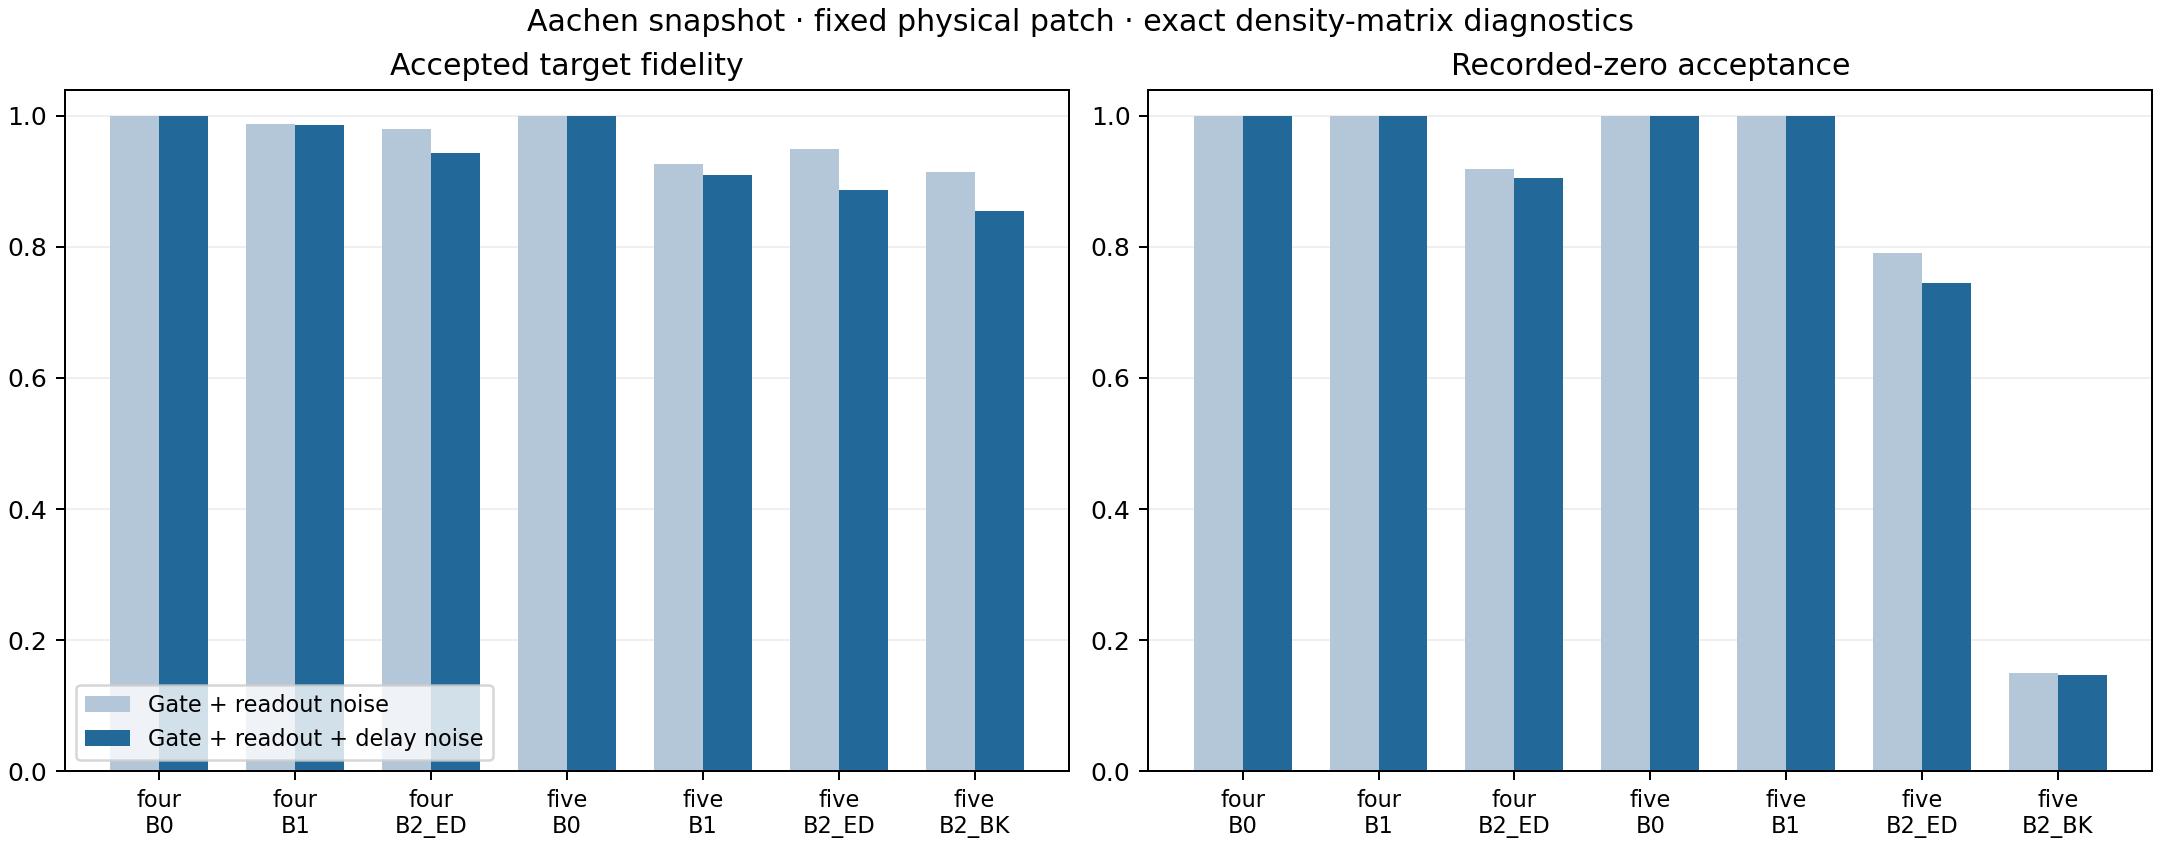

In [5]:
display(Image(filename=str(OUTPUT / 'noisy_comparison.png')))

## 4. Separate loss from logical distortion

A recorded zero syndrome does not guarantee the final state is in the
codespace. Check faults and late relaxation, especially during readout, can
leave accepted data outside it. Codespace population and within-codespace
logical fidelity below are **diagnostics**. The reported main fidelity includes
both codespace loss and logical distortion; no simulator-only filter improves
the delivered output.

B0/B1 accept every shot. B2_ED rejects recorded nonzero syndromes. B2_BK has
ideal acceptance 1/6 even without errors. All rows use each strategy's own
completion time; B0/B1 have no syndrome-readout wait. A shared downstream use
time would require additional storage waits for the faster preparations.

In [6]:
table = ['| Code / strategy | Full fidelity | Codespace population | Logical fidelity within codespace | Accepted fraction with nonzero true syndrome |',
         '|---|---:|---:|---:|---:|']
for row in report['rows']:
    r = row['full']
    table.append(f"| {row['code']}/{row['strategy']} | {r['fidelity']:.6f} | {r['codespace_population']:.6f} | {r['fidelity_conditioned_on_codespace_diagnostic']:.6f} | {r['accepted_fraction_from_nonzero_true_syndrome']:.6f} |")
display(Markdown('\n'.join(table)))
for row in report['rows']:
    if row['strategy'].startswith('B2'):
        delta = row['no_delay']['fidelity'] - row['full']['fidelity']
        print(f"{row['code']}/{row['strategy']}: omitting delays overstates fidelity by {100*delta:.2f} percentage points")

| Code / strategy | Full fidelity | Codespace population | Logical fidelity within codespace | Accepted fraction with nonzero true syndrome |
|---|---:|---:|---:|---:|
| four/B0 | 0.999792 | 1.000000 | 0.999792 | 0.000000 |
| four/B1 | 0.985589 | 0.987178 | 0.998391 | 0.000000 |
| four/B2_ED | 0.943088 | 0.945341 | 0.997616 | 0.000309 |
| five/B0 | 0.999784 | 1.000000 | 0.999784 | 0.000000 |
| five/B1 | 0.908950 | 0.913418 | 0.995109 | 0.000000 |
| five/B2_ED | 0.886818 | 0.894925 | 0.990941 | 0.000627 |
| five/B2_BK | 0.854524 | 0.856809 | 0.997334 | 0.006781 |

four/B2_ED: omitting delays overstates fidelity by 3.70 percentage points
five/B2_ED: omitting delays overstates fidelity by 6.21 percentage points
five/B2_BK: omitting delays overstates fidelity by 5.89 percentage points


## 5. Recorded syndrome counts and uncertainty

These Wilson intervals apply to the finite-shot acceptance estimate. The exact
model fidelities and probabilities above have no sampling error; model mismatch
with a physical device is a separate limitation. Bitstrings are s[m−1]…s[0].

In [7]:
table = ['| Code / strategy | Exact acceptance | Sampled acceptance | Wilson 95% interval |',
         '|---|---:|---:|---|']
for row in report['rows']:
    r = row['full']
    lo, hi = r['acceptance_wilson_95_interval']
    table.append(f"| {row['code']}/{row['strategy']} | {r['acceptance']:.6f} | {r['acceptance_sampled']:.6f} | [{lo:.6f}, {hi:.6f}] |")
display(Markdown('\n'.join(table)))
selected = next(r for r in report['rows'] if r['code'] == 'four' and r['strategy'] == 'B2_ED')
print('four/B2_ED raw recorded counts:', selected['full']['syndrome_counts'])

| Code / strategy | Exact acceptance | Sampled acceptance | Wilson 95% interval |
|---|---:|---:|---|
| four/B0 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| four/B1 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| four/B2_ED | 0.905051 | 0.899048 | [0.892336, 0.905386] |
| five/B0 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| five/B1 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| five/B2_ED | 0.744221 | 0.740112 | [0.730504, 0.749495] |
| five/B2_BK | 0.147074 | 0.151489 | [0.143889, 0.159416] |

four/B2_ED raw recorded counts: {'110': 13, '001': 205, '100': 157, '101': 82, '000': 7365, '010': 260, '111': 14, '011': 96}


## 6. Inspect and replay the saved schedule

The QPY files preserve the exact native circuits used for these results.
Re-synthesizing a Clifford circuit in another process/version may change gate
ordering and routing. The replay below uses the saved circuit, physical mapping,
and seed. Calibration file hashes are checked against the current local snapshot.
The original measured circuit is saved; simulator snapshots are added only for
analysis. The saved state is reordered into logical data order, with spectator
wires traced out.

In [8]:
for name, info in report['backend']['snapshot_files'].items():
    assert info['sha256'] == provenance['snapshot_files'][name]['sha256']
res = selected['resources']
print('Data physical qubits at delivery:', res['final_data_physical_qubits'])
print('Syndrome physical qubits in bit order:', res['syndrome_physical_qubits_in_bit_order'])
print('Total duration (µs):', res['duration_seconds']*1e6)
print('Data wait during syndrome readout (µs):', res['syndrome_readout_wait_seconds']*1e6)
print('Idle time by local physical wire (µs):', np.array(res['idle_seconds_by_local_wire'])*1e6)
with (OUTPUT / 'circuits' / 'four_B2_ED.qpy').open('rb') as f:
    saved_circuit = qpy.load(f)[0]
replay = ScheduledPreparation(
    build_preparation(CODES['four'], 'B2_ED'), saved_circuit,
    tuple(res['final_data_local_wires']), tuple(res['syndrome_local_wires_in_bit_order']), res,
)
replayed, accepted_rho = simulate_scheduled(replay, backend, mode='full', shots=SHOTS, seed=SEED)
assert np.isclose(replayed['fidelity'], selected['full']['fidelity'])
assert np.isclose(replayed['acceptance'], selected['full']['acceptance'])
assert replayed['syndrome_counts'] == selected['full']['syndrome_counts']
print('Saved-circuit replay agrees, including seeded counts.')
print(saved_circuit.draw(output='text', fold=120))

Data physical qubits at delivery: [5, 3, 2, 16]
Syndrome physical qubits in bit order: [1, 4, 23]
Total duration (µs): 5.424
Data wait during syndrome readout (µs): 2.584
Idle time by local physical wire (µs): [2.952 3.552 1.872 4.588 2.14  5.024 2.64  5.424 5.424]


Saved-circuit replay agrees, including seeded counts.
global phase: 7π/4
                ┌────────┐       ┌────┐  ┌──────────┐   ┌────┐           ┌────┐         ┌────┐   ┌────┐   »
   q_0 -> 0 ────┤ Rz(-π) ├───────┤ √X ├──┤ Rz(3π/4) ├───┤ √X ├───■───────┤ √X ├───────■─┤ √X ├─■─┤ √X ├─■─»
             ┌──┴────────┴──┐ ┌──┴────┴─┐└──┬────┬──┘┌──┴────┴─┐ │ ┌─────┴────┴─────┐ │ └────┘ │ └────┘ │ »
   q_1 -> 1 ─┤ Delay(8[dt]) ├─┤ Rz(π/2) ├───┤ √X ├───┤ Rz(π/2) ├─■─┤ Delay(109[dt]) ├─┼────────┼────────┼─»
            ┌┴──────────────┤ └┬────────┤   ├────┤   ├─────────┤   └────────────────┘ │ ┌────┐ │ ┌────┐ │ »
   q_2 -> 2 ┤ Delay(33[dt]) ├──┤ Rz(-π) ├───┤ √X ├───┤ Rz(π/2) ├──────────────────────■─┤ √X ├─■─┤ √X ├─■─»
            ├───────────────┴┐┌┴────────┤   ├────┤   ├─────────┤                        └────┘   └────┘   »
   q_3 -> 3 ┤ Delay(100[dt]) ├┤ Rz(π/2) ├───┤ √X ├───┤ Rz(π/2) ├──────────────────────────────────────────»
            ├────────────────┤└┬────────┤   ├────┤   ├─────────

## 7. Isolate syndrome readout error

Readout assignment error was already included in the preparation results above.
It can reject a true zero syndrome and accept a nonzero one. The latter changes
the accepted data ensemble. It is a classical assignment channel, not a new
quantum operation on the data. A true zero syndrome is not proof of a perfect
logical output.

The following ablation disables **only syndrome assignment error**. Gate noise,
delay noise, and the full 2.584 µs data wait during readout remain unchanged.
B0/B1 have no syndrome readout. Their exact preparation fidelity therefore does
not include any destructive data-readout error.

The analysis reuses the saved QPY circuits. Set `RERUN_QUALITY=True` to repeat
the ablation and measurement experiments; otherwise the saved results are used.

In [9]:
from analyze_readout import run_analysis, readout_table, quality_table

RERUN_QUALITY = False
quality_path = OUTPUT / 'readout_and_fidelity.json'
if RERUN_QUALITY or not quality_path.exists():
    quality = run_analysis(OUTPUT, shots=SHOTS, seed=SEED)
else:
    quality = json.loads(quality_path.read_text())

for original, measured in zip(report['rows'], quality['rows']):
    assert (original['code'], original['strategy']) == (measured['code'], measured['strategy'])
    assert np.isclose(original['full']['fidelity'], measured['exact_preparation_fidelity'])
display(Markdown(readout_table(quality)))

| Protocol | Acceptance without → with readout error | Fidelity without → with readout error | Nonzero true syndrome among accepted |
|---|---:|---:|---:|
| four/B2_ED | 91.703% → 90.505% | 94.334% → 94.309% | 0.0309% |
| five/B2_ED | 75.679% → 74.422% | 88.725% → 88.682% | 0.0627% |
| five/B2_BK | 14.864% → 14.707% | 86.017% → 85.452% | 0.6781% |

## 8. Estimate state quality from finite-shot Pauli measurements

The earlier sections used finite shots only for acceptance. Here **fidelity is
estimated from measurement counts**. Expand the full physical target projector
as a weighted sum of Pauli strings and sum their measured expectations:
`F_est = c_I + sum_P c_P * mean(P | recorded syndrome = 0)`.

For each nonidentity term, prepare fresh copies, apply local basis rotations,
and measure data parity. X uses H; Y uses S† then H; Z needs no rotation.
Keep the original recorded-zero syndrome shots. There are **23 settings** for
the four-qubit target and **63** for the five-qubit target. Each setting uses
8,192 attempted shots; rejection reduces the accepted sample count. Analysis
copies are consumed, while preparation circuits still leave reusable outputs.

The existing routing and timing are frozen. Analysis rotations begin after the
original output delivery boundary. Their native-gate noise, padding delays, and
data assignment errors are included. The target-projector expansion includes
codespace loss; logical X/Y/Z alone would not suffice.

Two estimates use the same counts: **raw parity** and **data-readout-corrected
parity**. Correction uses the snapshot's known assignment matrices. Syndrome
bits are never corrected, so the estimate refers to the actually accepted state.

| Protocol | Exact preparation fidelity | Raw finite-shot estimate | Data-readout-mitigated estimate | Approx. 95% statistical interval (mitigated) | Settings × shots |
|---|---:|---:|---:|---:|---:|
| four/B0 | 0.999792 | 0.993214 | 0.996365 | [0.988556, 1.004173] | 2 × 8,192 |
| four/B1 | 0.985589 | 0.840238 | 0.984672 | [0.980214, 0.989129] | 23 × 8,192 |
| four/B2_ED | 0.943088 | 0.809648 | 0.941372 | [0.936544, 0.946201] | 23 × 8,192 |
| five/B0 | 0.999784 | 0.991297 | 0.994436 | [0.985462, 1.003410] | 3 × 8,192 |
| five/B1 | 0.908950 | 0.770784 | 0.908311 | [0.904752, 0.911870] | 63 × 8,192 |
| five/B2_ED | 0.886818 | 0.747499 | 0.885097 | [0.880877, 0.889317] | 63 × 8,192 |
| five/B2_BK | 0.854524 | 0.720743 | 0.853481 | [0.843772, 0.863191] | 63 × 8,192 |

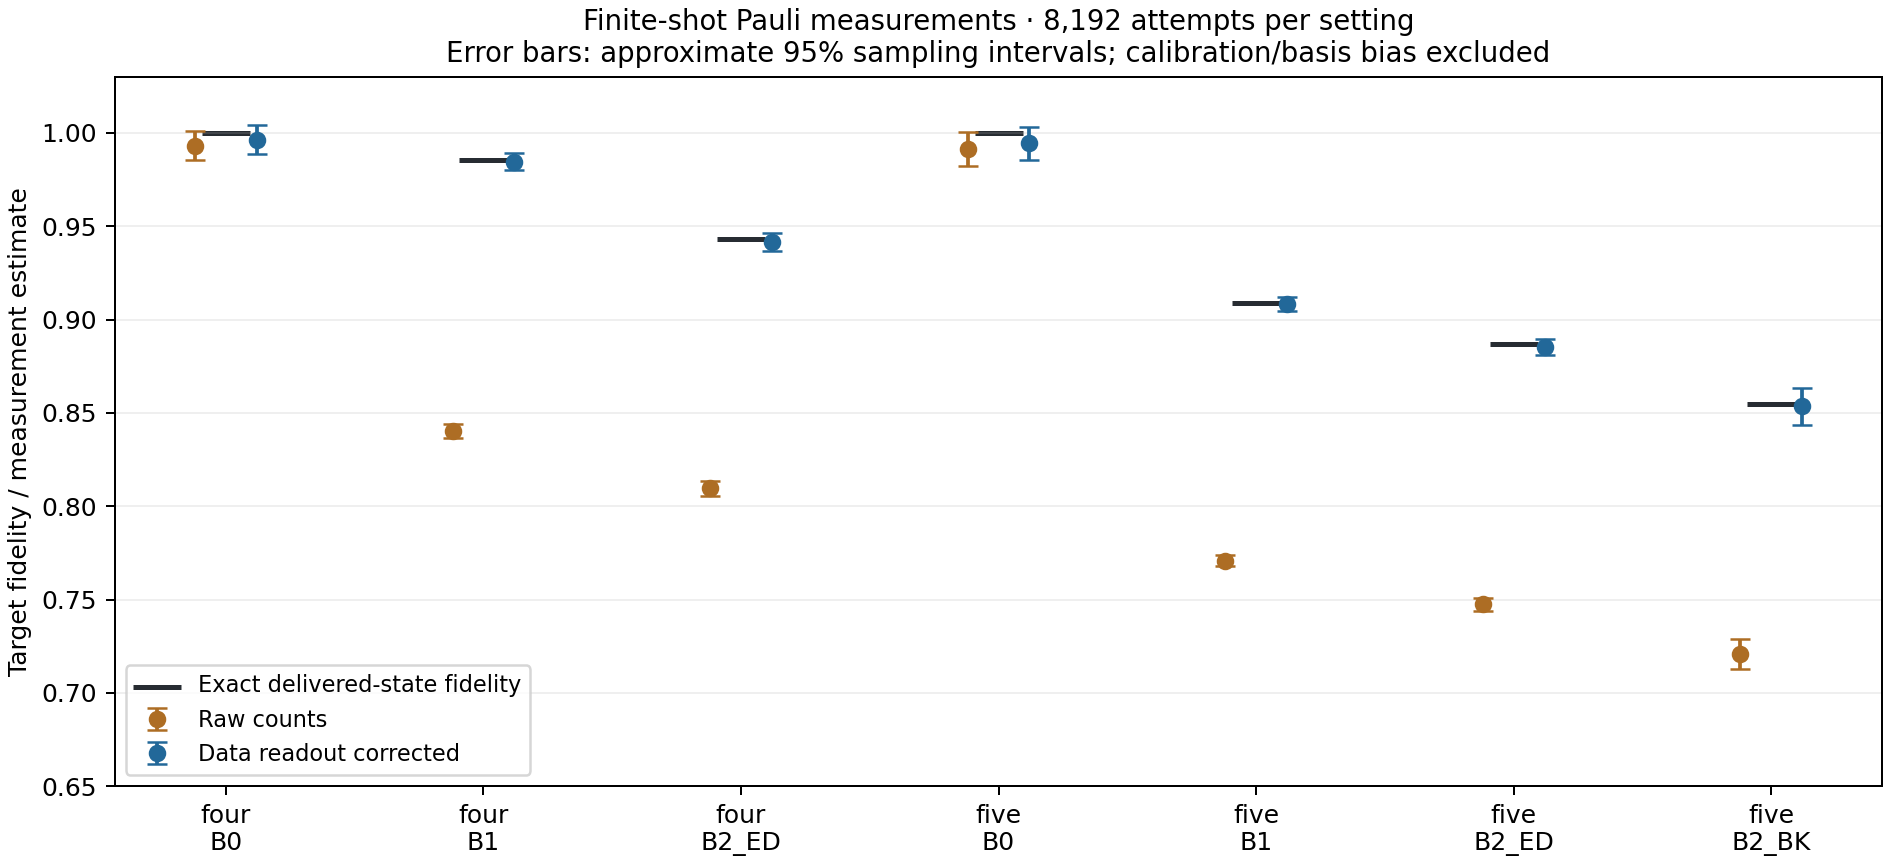

Total attempted quality-measurement shots: 1966080


In [10]:
display(Markdown(quality_table(quality)))
display(Image(filename=str(OUTPUT / 'finite_shot_fidelity.png')))
print('Total attempted quality-measurement shots:', quality['total_quality_measurement_shots'])

### Sampling uncertainty versus measurement bias

For data assignment A[true, recorded], the corrected parity weights solve
`A @ w = [1, -1]`. Products of single-qubit weights give each Pauli-string score.
For symmetric assignment error e, this divides parity by `(1 - 2e)` on each
nonidentity factor. This removes data assignment bias under the stated model.

The error bars are approximate 95% statistical intervals from independent
settings. Conservative Hoeffding/union-bound intervals are also saved. Neither
interval includes calibration uncertainty or basis-rotation/delay bias. The
assignment matrices are treated as exact in this simulation; a hardware
measurement would need calibration and its uncertainty. Estimates and intervals
are left unclipped, so a statistical fluctuation can exceed one.

The simulator-only infinite-shot measurement score below separates residual
measurement bias from finite-shot fluctuations. It is not used to compute the
estimate. The remaining difference from the exact delivered-state fidelity is
due to the noisy analysis rotations and waits.

In [11]:
table = ['| Protocol | Exact delivered-state fidelity | Infinite-shot raw score | Infinite-shot data-readout-corrected score | Remaining corrected bias |',
         '|---|---:|---:|---:|---:|']
for row in quality['rows']:
    r = row['finite_shot']
    raw = r['raw']['infinite_shot_measurement_score_diagnostic']
    corrected = r['data_readout_mitigated']['infinite_shot_measurement_score_diagnostic']
    bias = corrected - row['exact_preparation_fidelity']
    table.append(f"| {row['code']}/{row['strategy']} | {row['exact_preparation_fidelity']:.6f} | {raw:.6f} | {corrected:.6f} | {bias:+.6f} |")
display(Markdown('\n'.join(table)))

| Protocol | Exact delivered-state fidelity | Infinite-shot raw score | Infinite-shot data-readout-corrected score | Remaining corrected bias |
|---|---:|---:|---:|---:|
| four/B0 | 0.999792 | 0.996602 | 0.999774 | -0.000018 |
| four/B1 | 0.985589 | 0.840401 | 0.984940 | -0.000649 |
| four/B2_ED | 0.943088 | 0.810400 | 0.942383 | -0.000705 |
| five/B0 | 0.999784 | 0.996603 | 0.999775 | -0.000009 |
| five/B1 | 0.908950 | 0.770542 | 0.908027 | -0.000923 |
| five/B2_ED | 0.886818 | 0.747860 | 0.885548 | -0.001270 |
| five/B2_BK | 0.854524 | 0.720857 | 0.853304 | -0.001221 |

### Reconstruct the estimate using counts alone

This cell recomputes both four-qubit B2_ED estimates using only raw counts,
Pauli coefficients, and assignment matrices. It does not read an output density
matrix or simulator expectation value. QPY files in `quality_circuits` store
the measurement circuits without any simulator state-save instructions.

In [12]:
from logical_magic.noisy_fidelity import accepted_score, parity_weights

measured = next(r for r in quality['rows'] if r['code'] == 'four' and r['strategy'] == 'B2_ED')
sample = measured['finite_shot']
assignment = [np.asarray(a) for a in sample['data_assignment_matrices']]
for name, matrices in [('raw', None), ('data_readout_mitigated', assignment)]:
    estimate = sample['identity_coefficient']
    variance = 0.0
    for term in sample['terms']:
        weights = parity_weights(term['pauli'], matrices)
        score = accepted_score(term['counts'], n_syndrome=3, weights=weights)
        estimate += term['coefficient'] * score['expectation']
        variance += term['coefficient']**2 * score['variance_of_mean']
    assert np.isclose(estimate, sample[name]['fidelity_estimate'])
    print(f'{name}: {estimate:.6f} ± {1.96*np.sqrt(variance):.6f} (approx. 95% statistical interval)')
print('Accepted shots across settings:', sample['total_accepted_shots'])
print('First setting:', sample['terms'][0]['pauli'])
print('Its raw joint data/syndrome counts:', sample['terms'][0]['counts'])

raw: 0.809648 ± 0.004028 (approx. 95% statistical interval)
data_readout_mitigated: 0.941372 ± 0.004828 (approx. 95% statistical interval)
Accepted shots across settings: 170549
First setting: IIXX
Its raw joint data/syndrome counts: {'1110 101': 1, '1101 101': 1, '1111 110': 1, '1010 011': 4, '0101 100': 1, '1010 101': 1, '0101 110': 1, '1001 000': 31, '1000 111': 3, '1001 101': 2, '1000 010': 8, '0110 101': 2, '1100 011': 7, '0000 101': 2, '1011 111': 4, '1001 011': 2, '0010 100': 3, '1000 110': 4, '1010 010': 4, '1001 100': 3, '0100 101': 15, '0000 011': 5, '1011 001': 2, '1001 110': 1, '0011 001': 31, '1110 011': 12, '1111 010': 32, '0101 011': 1, '1110 001': 15, '0000 100': 11, '1111 001': 37, '1111 000': 1373, '0101 001': 2, '1010 110': 3, '1011 110': 2, '0101 000': 37, '1100 101': 1, '1101 011': 7, '0110 010': 3, '0100 001': 5, '1100 001': 25, '0010 011': 15, '1001 001': 3, '0110 001': 2, '0010 001': 15, '0101 010': 4, '0011 100': 6, '0001 010': 15, '0100 110': 4, '1111 011': 9,

## 9. Visualize the full circuit timing with Qiskit

The figures below use **Qiskit's `timeline_drawer`** with the exact saved native
circuits and calibrated Aachen durations. They show gates, delays, and readout;
the local snapshot does not supply analog pulse waveforms. Qiskit 2.4.1 no longer
includes Qiskit Pulse.

QPY preserves the gates and explicit delays, but not their start-time metadata.
`ALAPScheduleAnalysis` reconstructs those timestamps without recompilation.
Instruction identity, total duration, per-wire idle totals, and source-file
hashes are checked. Durations are in **microseconds**.

Blue bars are CZ gates, teal bars are native one-qubit gates, gray bars are
delays, and orange bars are ancilla readout. Virtual Rz updates have zero
duration and their symbols are hidden for readability. Each row is a physical
IBM qubit; D/S labels give its data/syndrome role **at output**, because routing
moves states between physical wires.

The first timing column includes input preparation/encoding and coherent
syndrome mapping. It is **not syndrome extraction alone**: the optimized
original circuit does not retain boundaries between those source stages.
All ancillas are measured together at the end. The data wait throughout that
**2.584 µs** readout window, so their state can change after syndrome mapping.

| Protocol | Preparation + syndrome mapping (µs) | Readout / data wait (µs) | Total (µs) |
|---|---:|---:|---:|
| four/B2_ED | 2.840 | 2.584 | 5.424 |
| five/B2_ED | 7.812 | 2.584 | 10.396 |
| five/B2_BK | 3.640 | 2.584 | 6.224 |

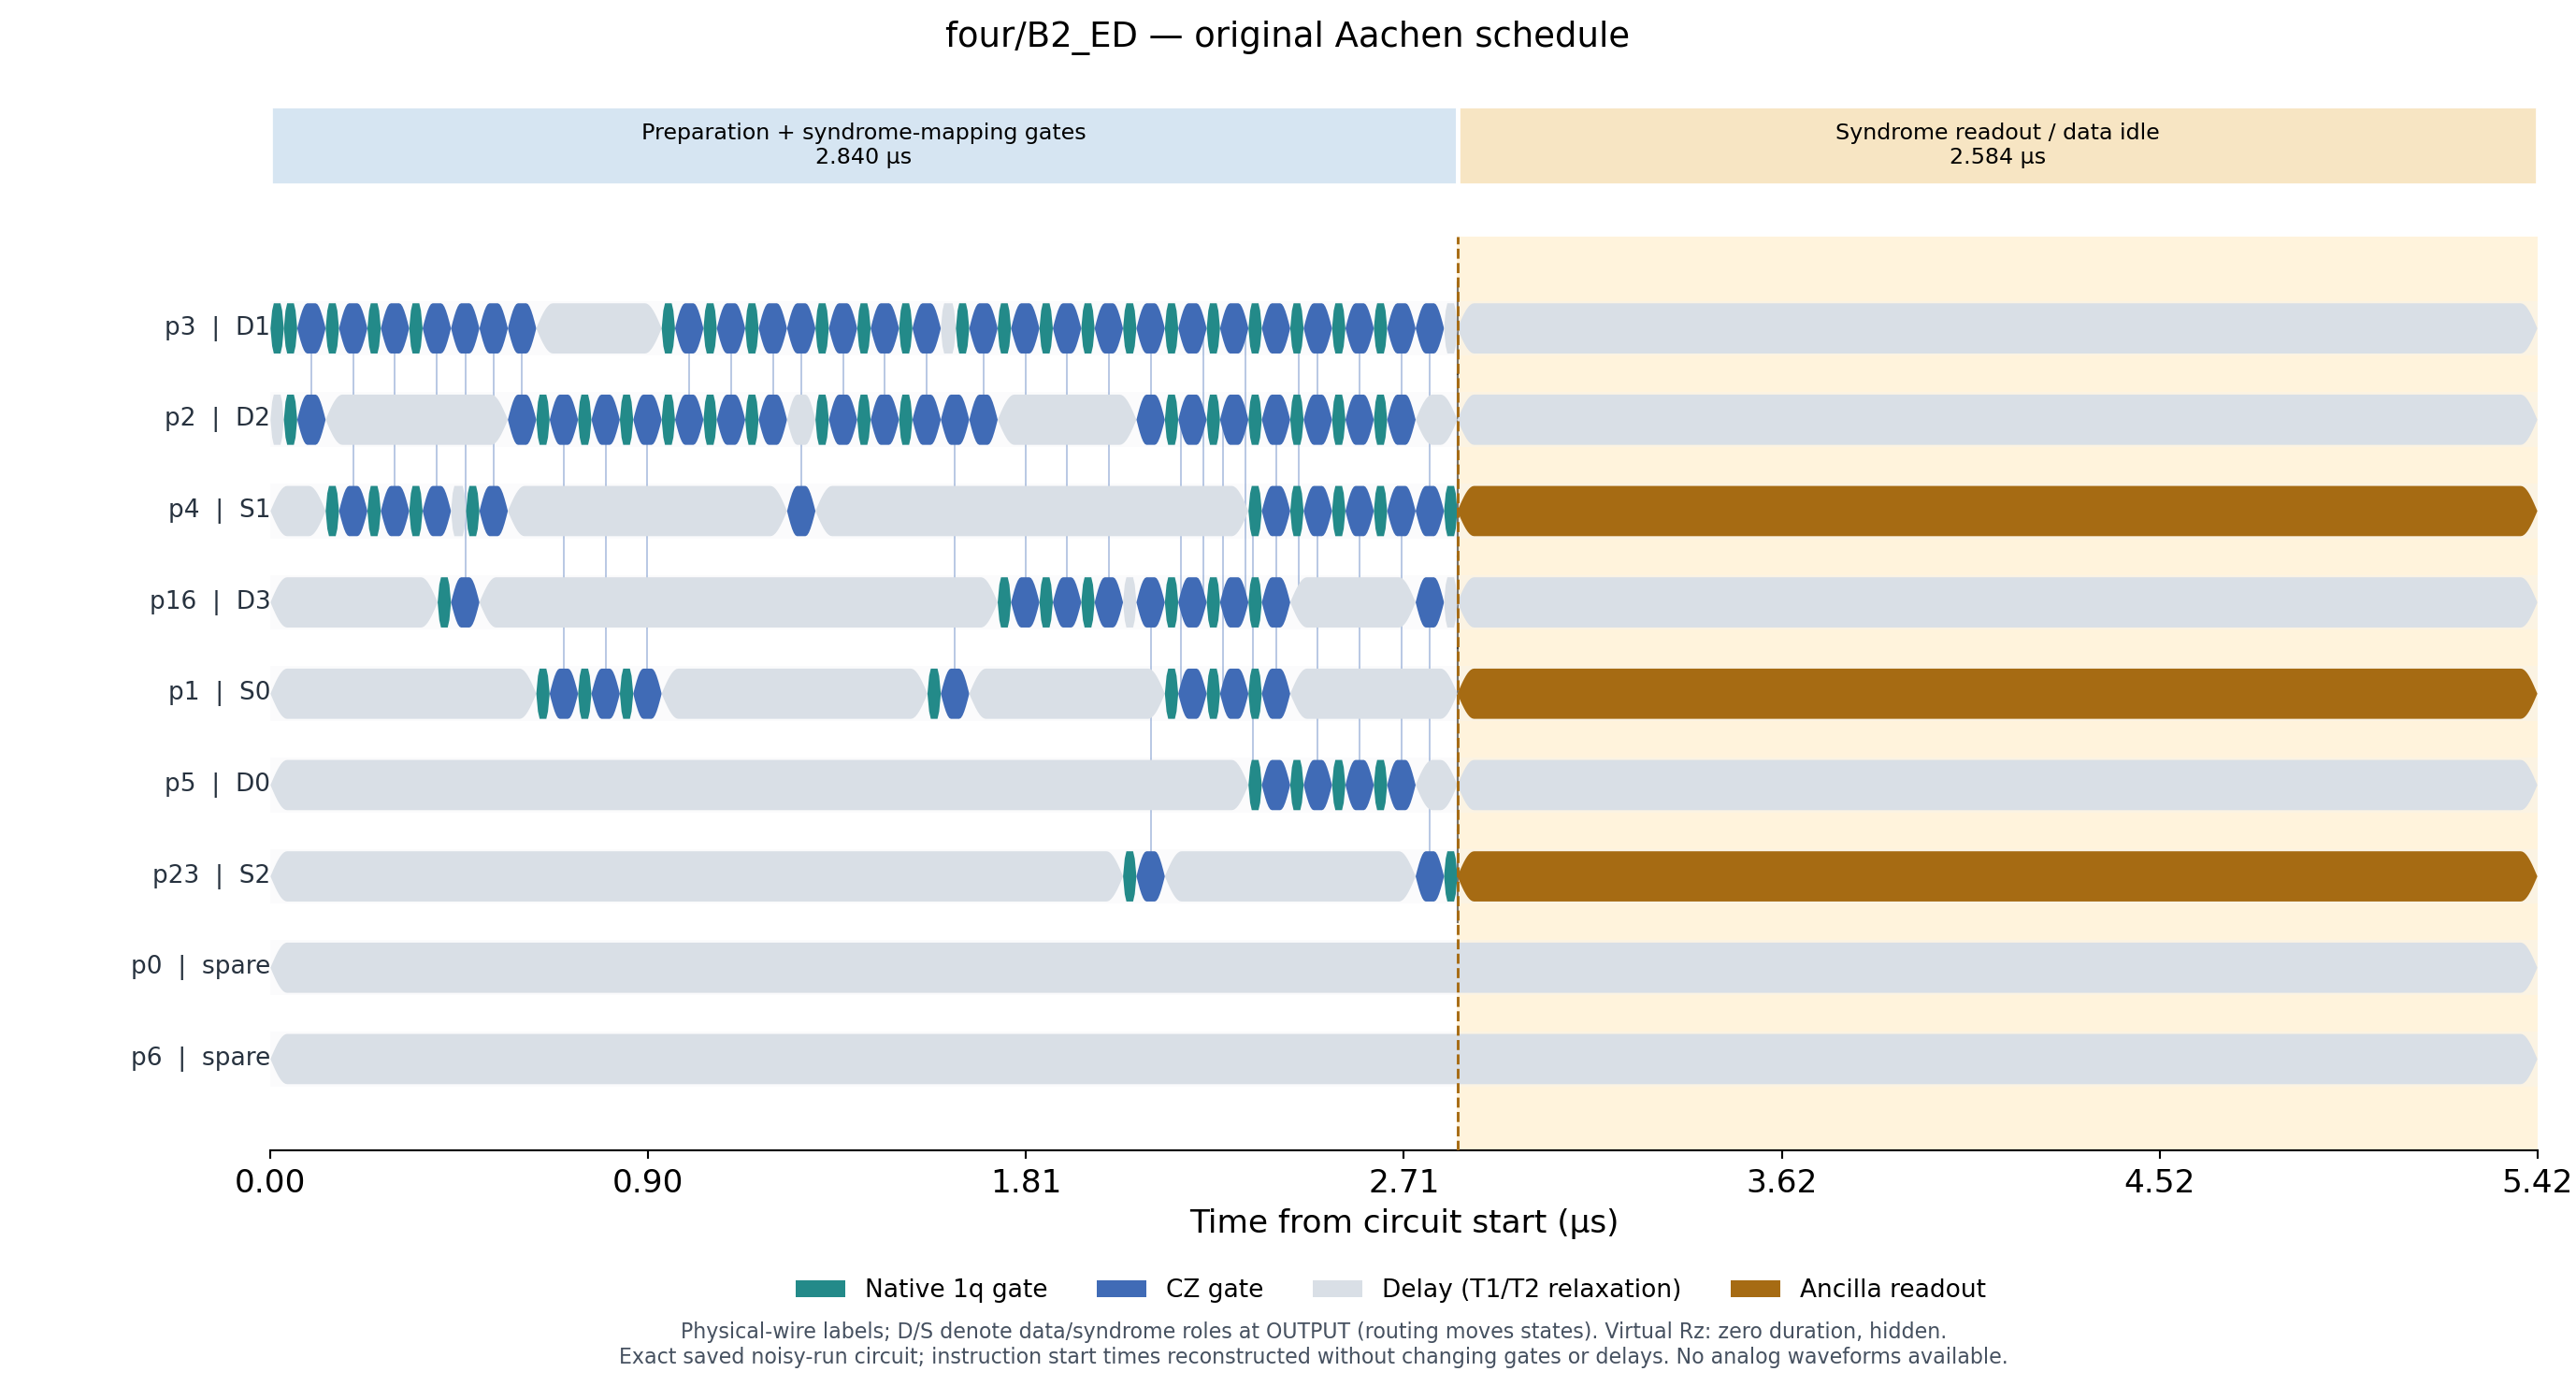

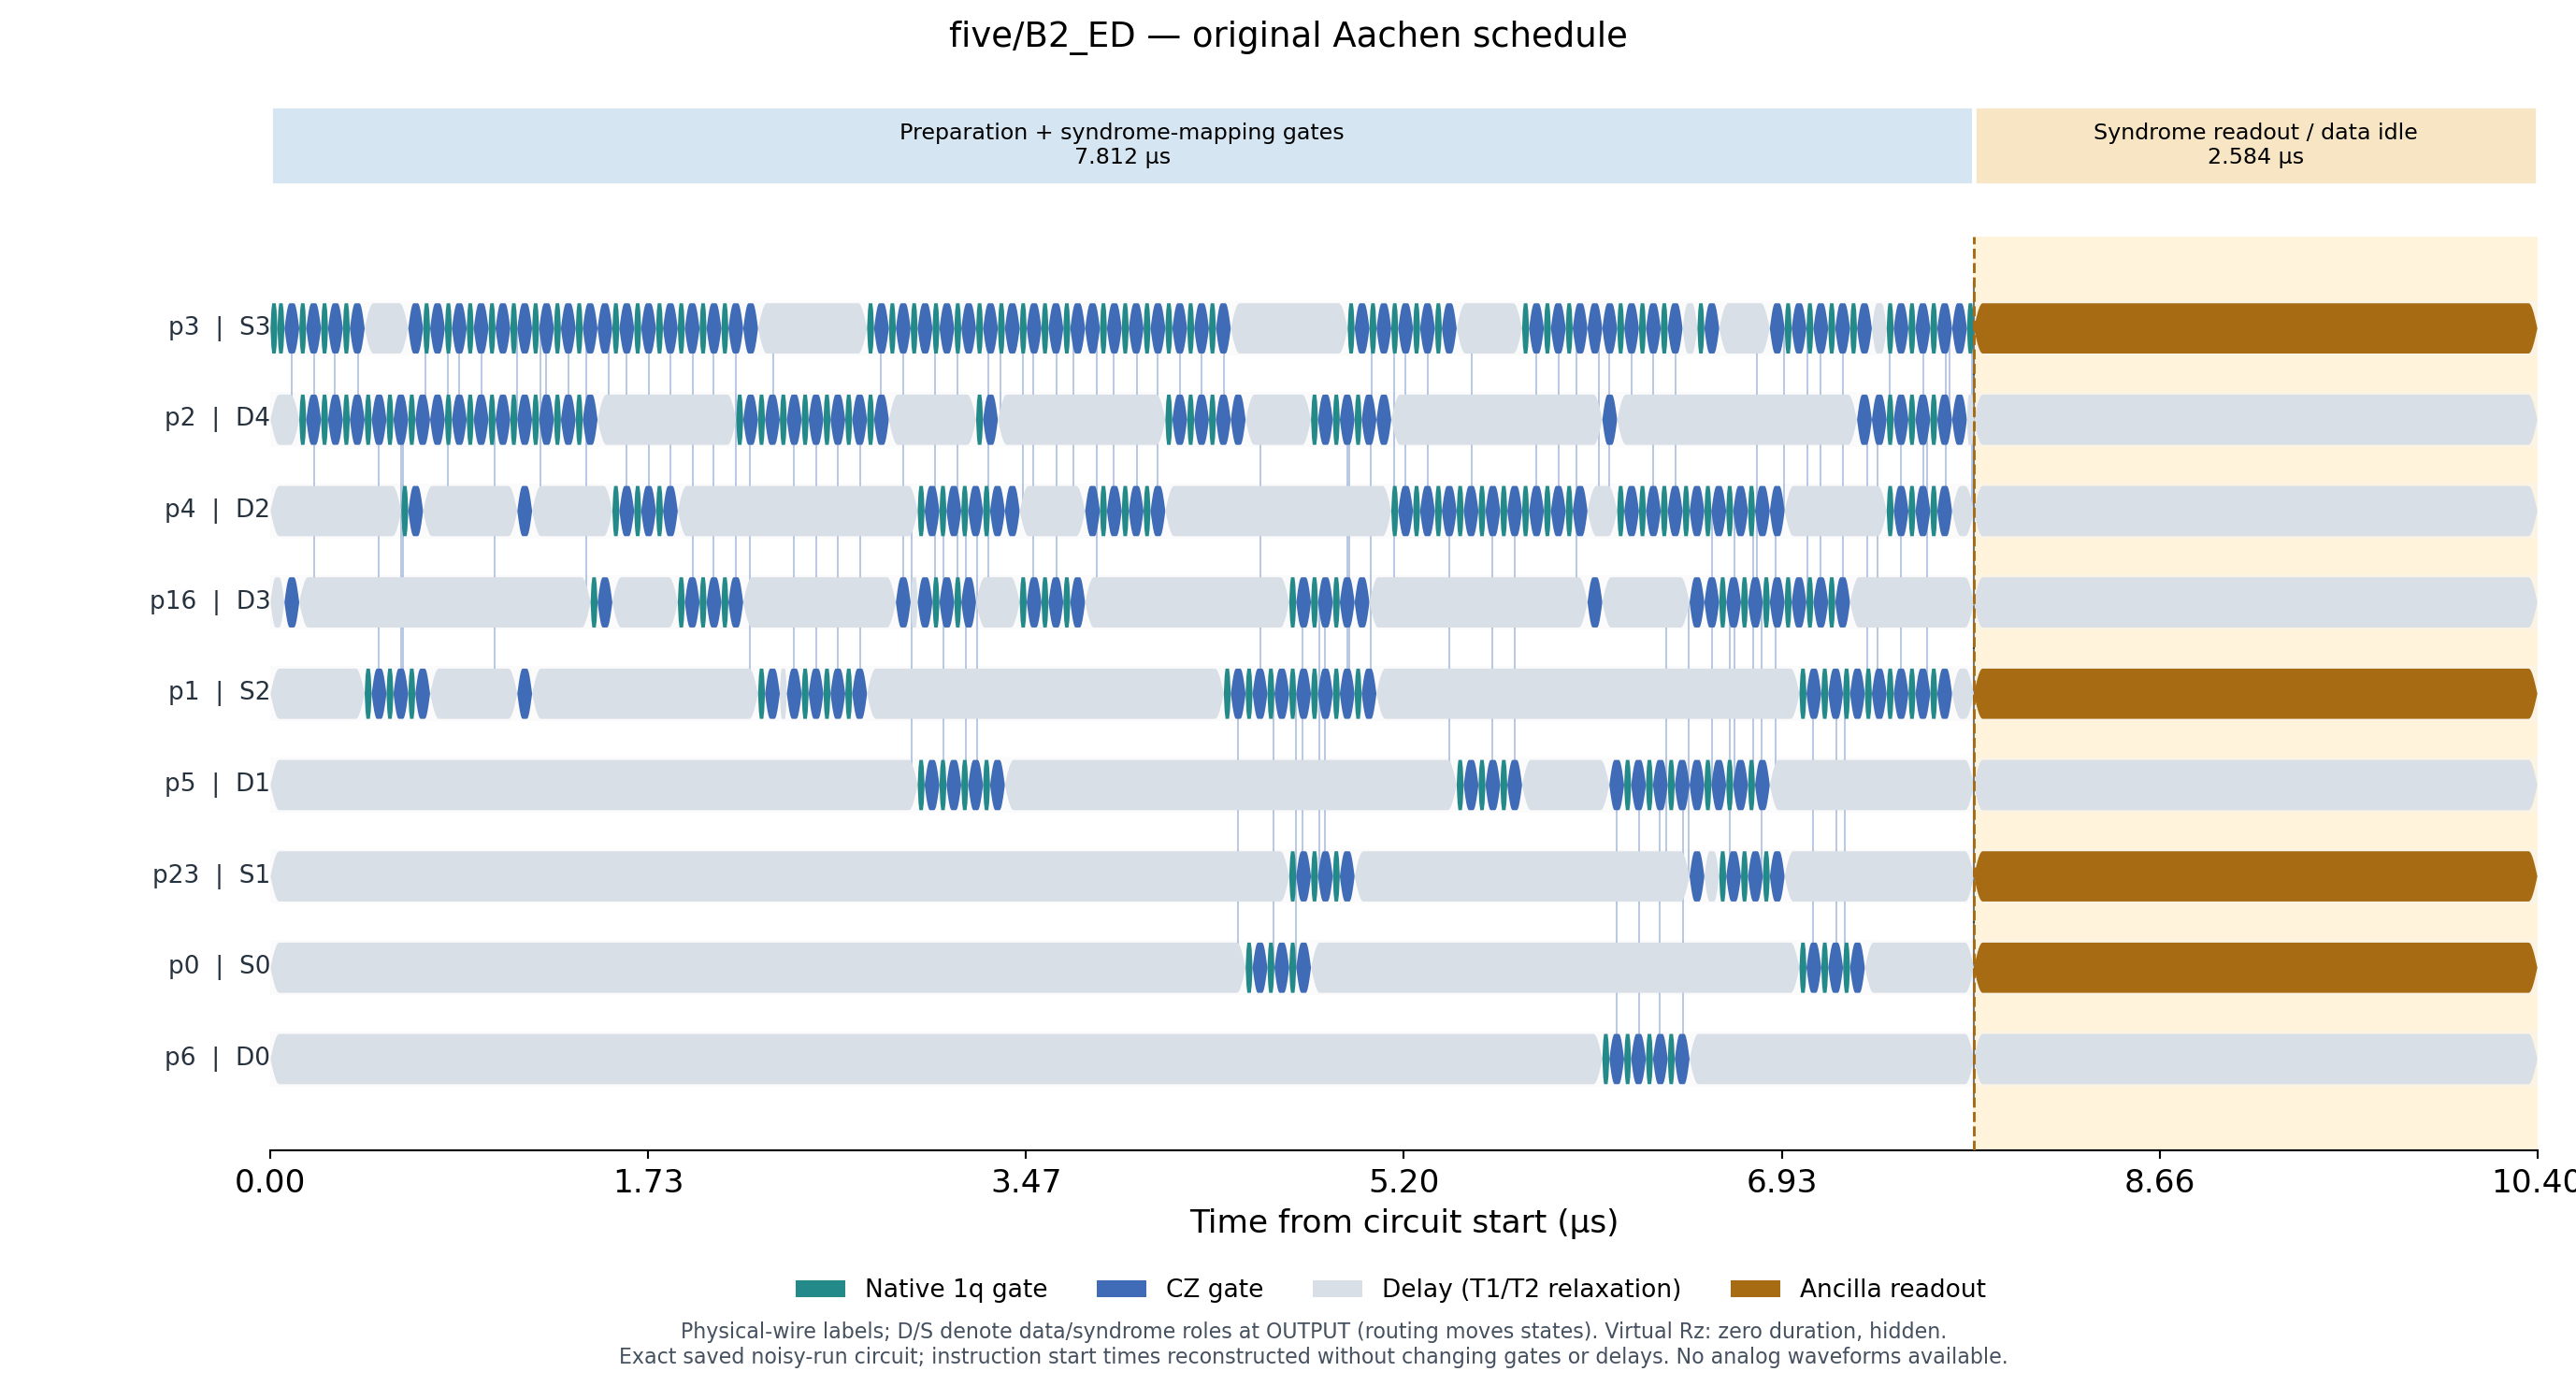

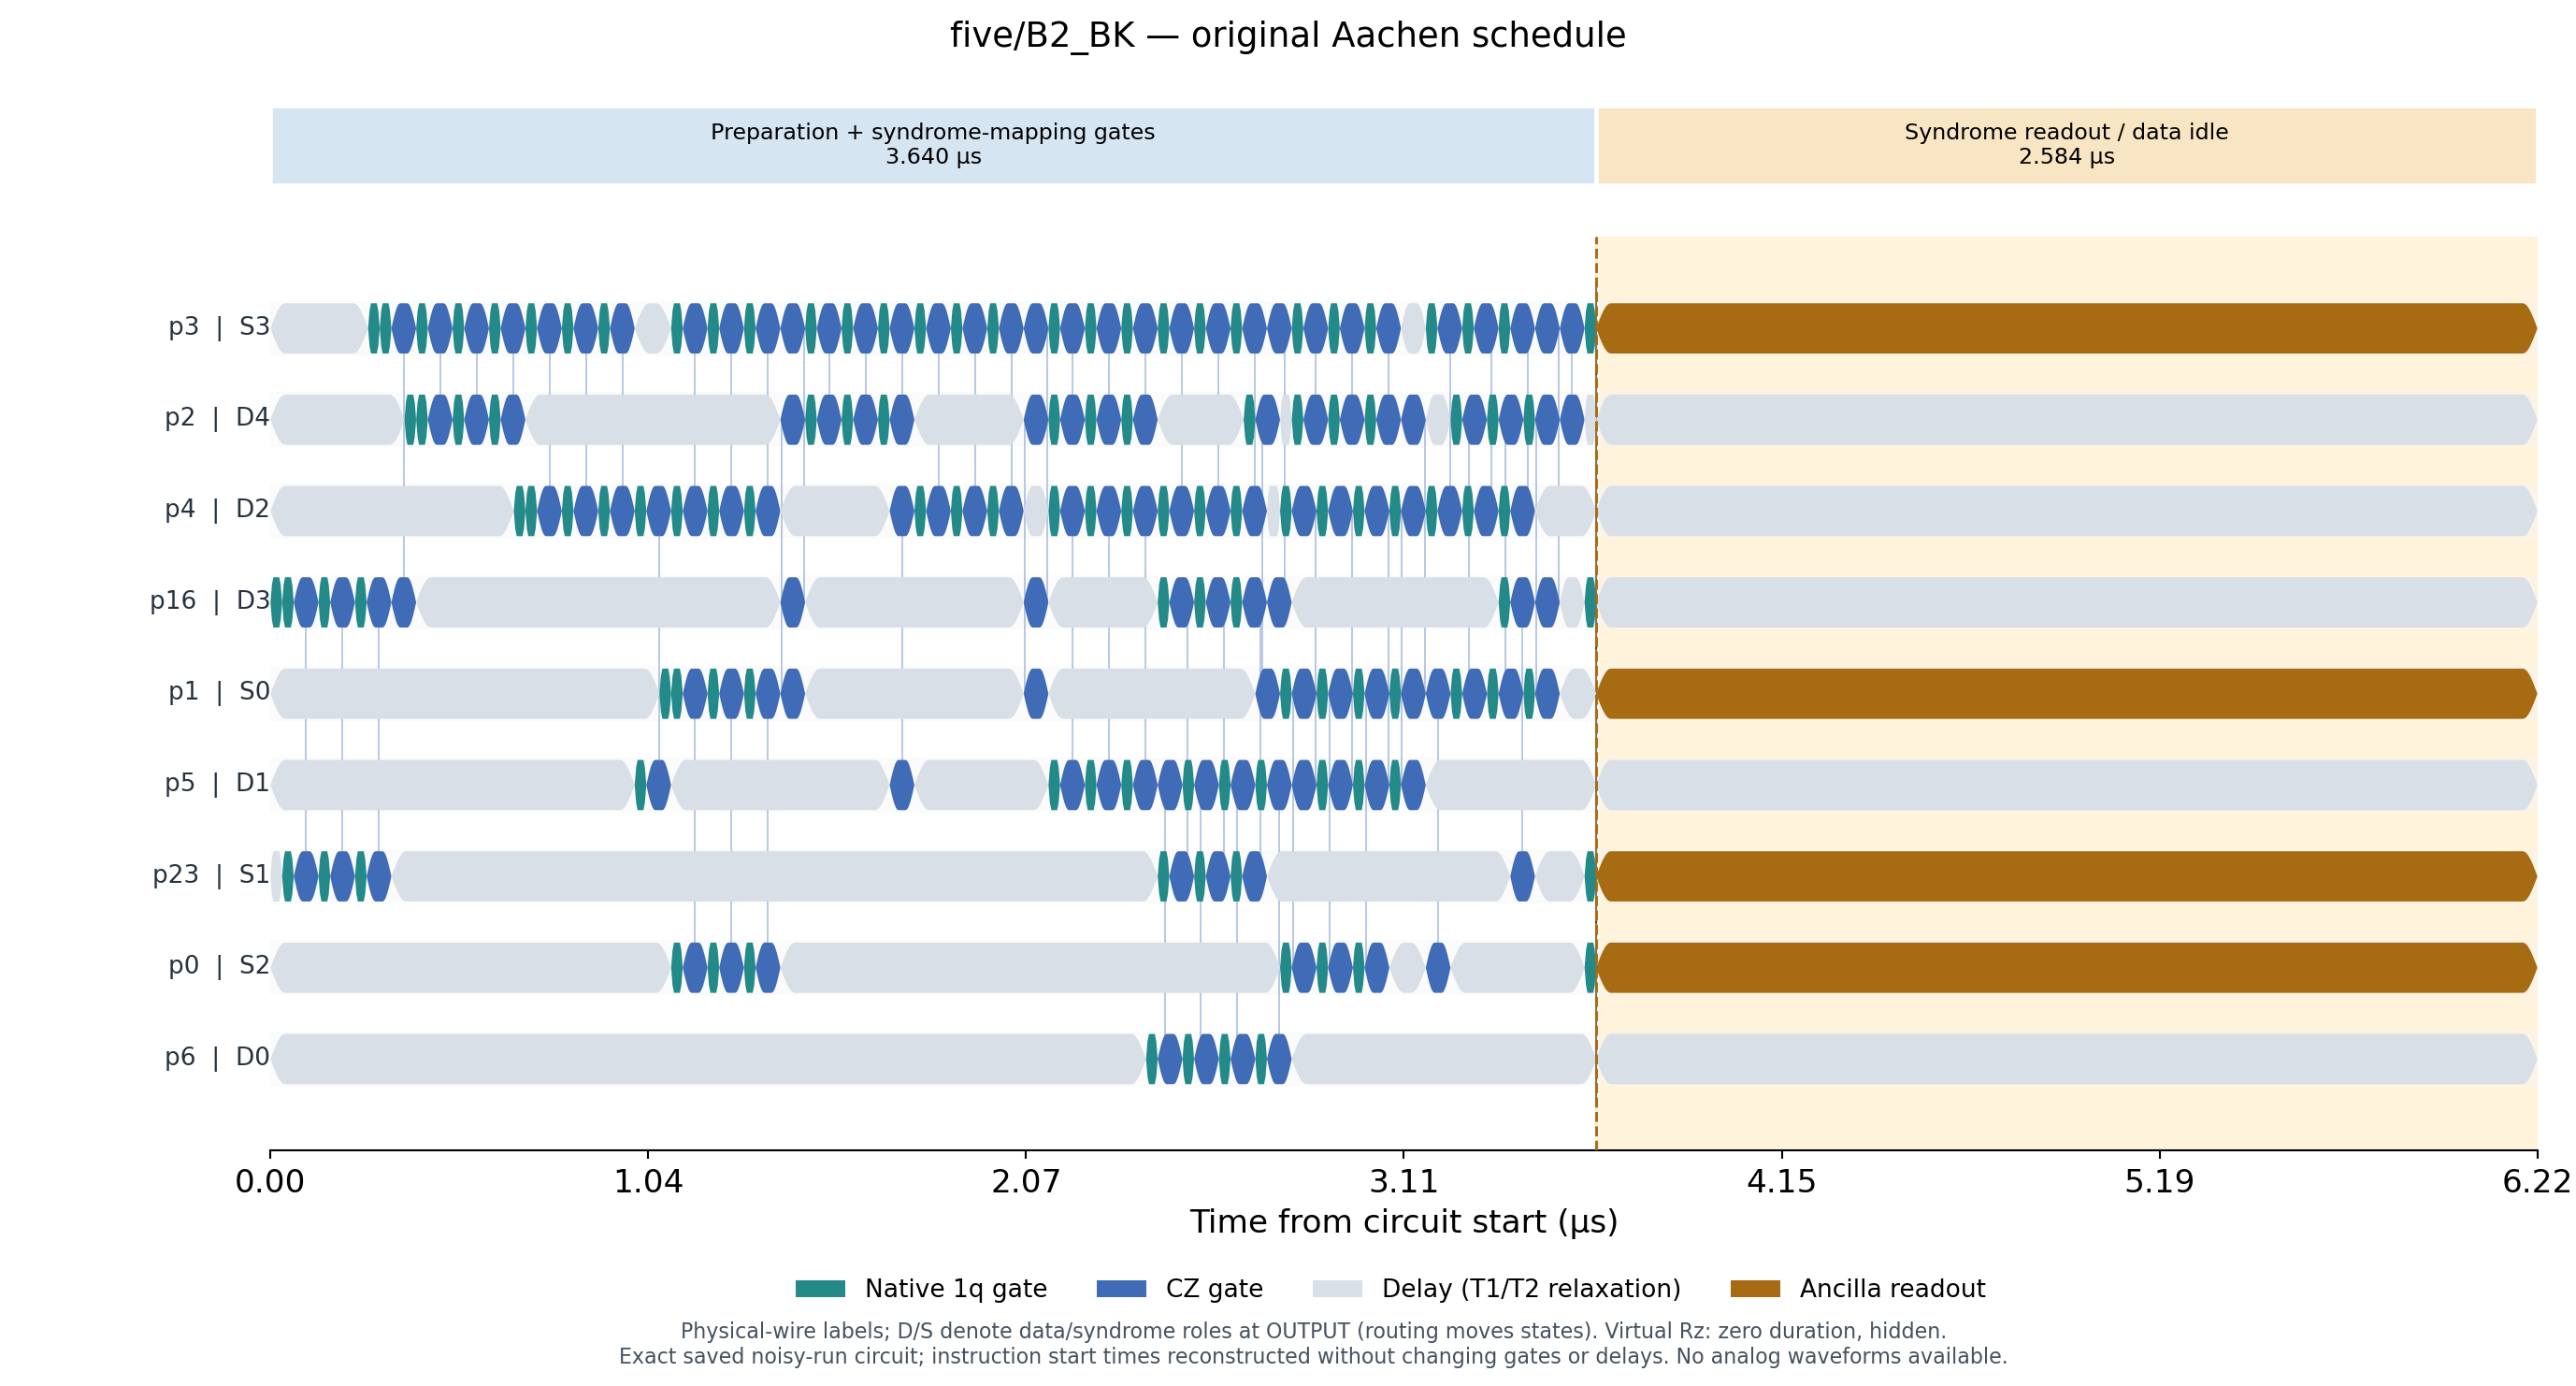

In [13]:
from draw_timelines import run_timelines

TIMELINES = OUTPUT / 'timelines'
timing_path = TIMELINES / 'timing_summary.json'
if not timing_path.exists():
    timing = run_timelines(OUTPUT)
else:
    timing = json.loads(timing_path.read_text())
table = ['| Protocol | Preparation + syndrome mapping (µs) | Readout / data wait (µs) | Total (µs) |',
         '|---|---:|---:|---:|']
for row in timing['rows']:
    r = row['original']
    table.append(f"| {row['code']}/{row['strategy']} | {r['coherent_phase_us']:.3f} | {r['readout_duration_us']:.3f} | {r['total_us']:.3f} |")
display(Markdown('\n'.join(table)))
for row in timing['rows']:
    label = f"{row['code']}_{row['strategy']}"
    display(Image(filename=str(TIMELINES / (label + '_original.png'))))

### Time each stabilizer check in a separate diagnostic compilation

To expose the stages, this diagnostic inserts barriers after preparation and
after every check, then compiles and schedules again. The P band is preparation;
S0, S1, etc. are the coherent stabilizer-mapping blocks. These extra barriers
prevent overlap/fusion across stages and can change routing, so **these durations
describe a different compilation**. They must not replace the timings of the
original noisy results. Section 10 runs a separate matched noise experiment on
these circuits.

The diagnostic's syndrome-extraction duration is the sum of the check blocks
plus the terminal readout. Ideal simulation verifies fidelity 1 and acceptance
1 for B2_ED, or 1/6 for B2_BK. The original result circuits remain unchanged.
Full plots, gate-region zooms, and PDF/SVG exports are in `results/noisy_aachen/timelines`.

| Protocol | Preparation (µs) | Check blocks (µs) | Readout (µs) | Checks + readout (µs) | Total (µs) |
|---|---:|---:|---:|---:|---:|
| four/B2_ED | 0.668 | 2.836 | 2.584 | 5.420 | 6.088 |
| five/B2_ED | 3.068 | 6.208 | 2.584 | 8.792 | 11.860 |
| five/B2_BK | 0.064 | 5.744 | 2.584 | 8.328 | 8.392 |

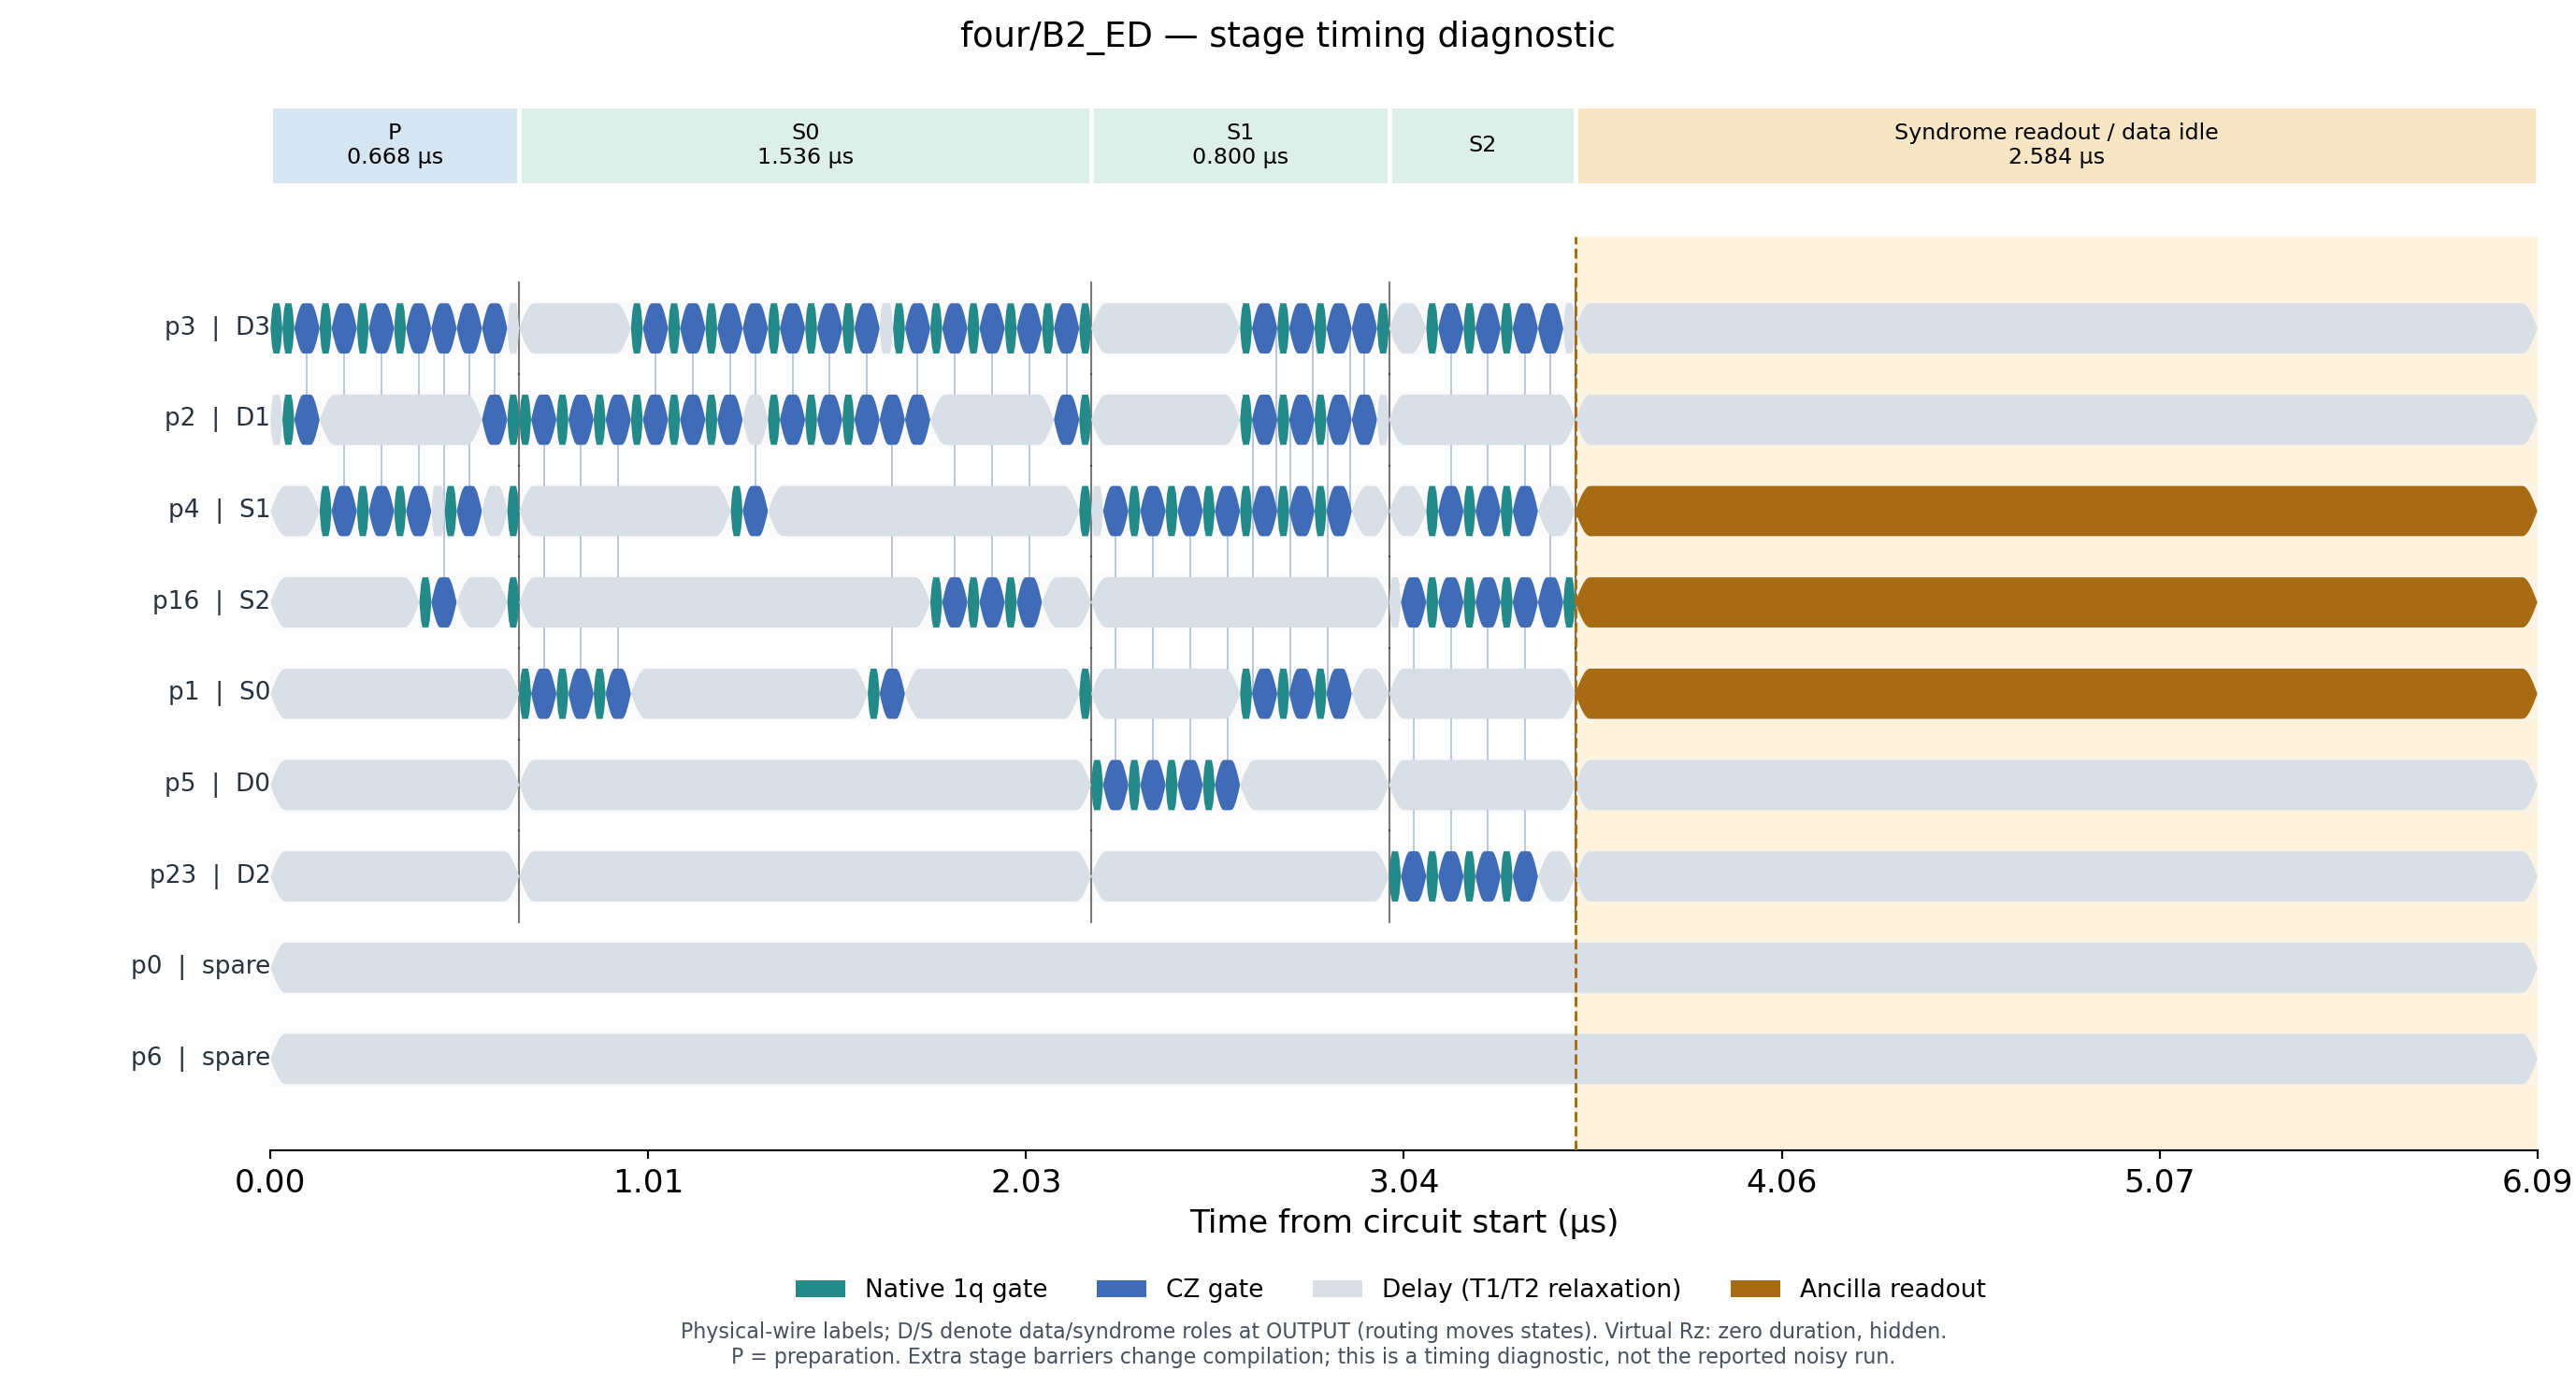

| Source stage | Duration (µs) |
|---|---:|
| prepare | 0.668 |
| check_0_XXXX | 1.536 |
| check_1_IIZZ | 0.800 |
| check_2_ZZII | 0.500 |

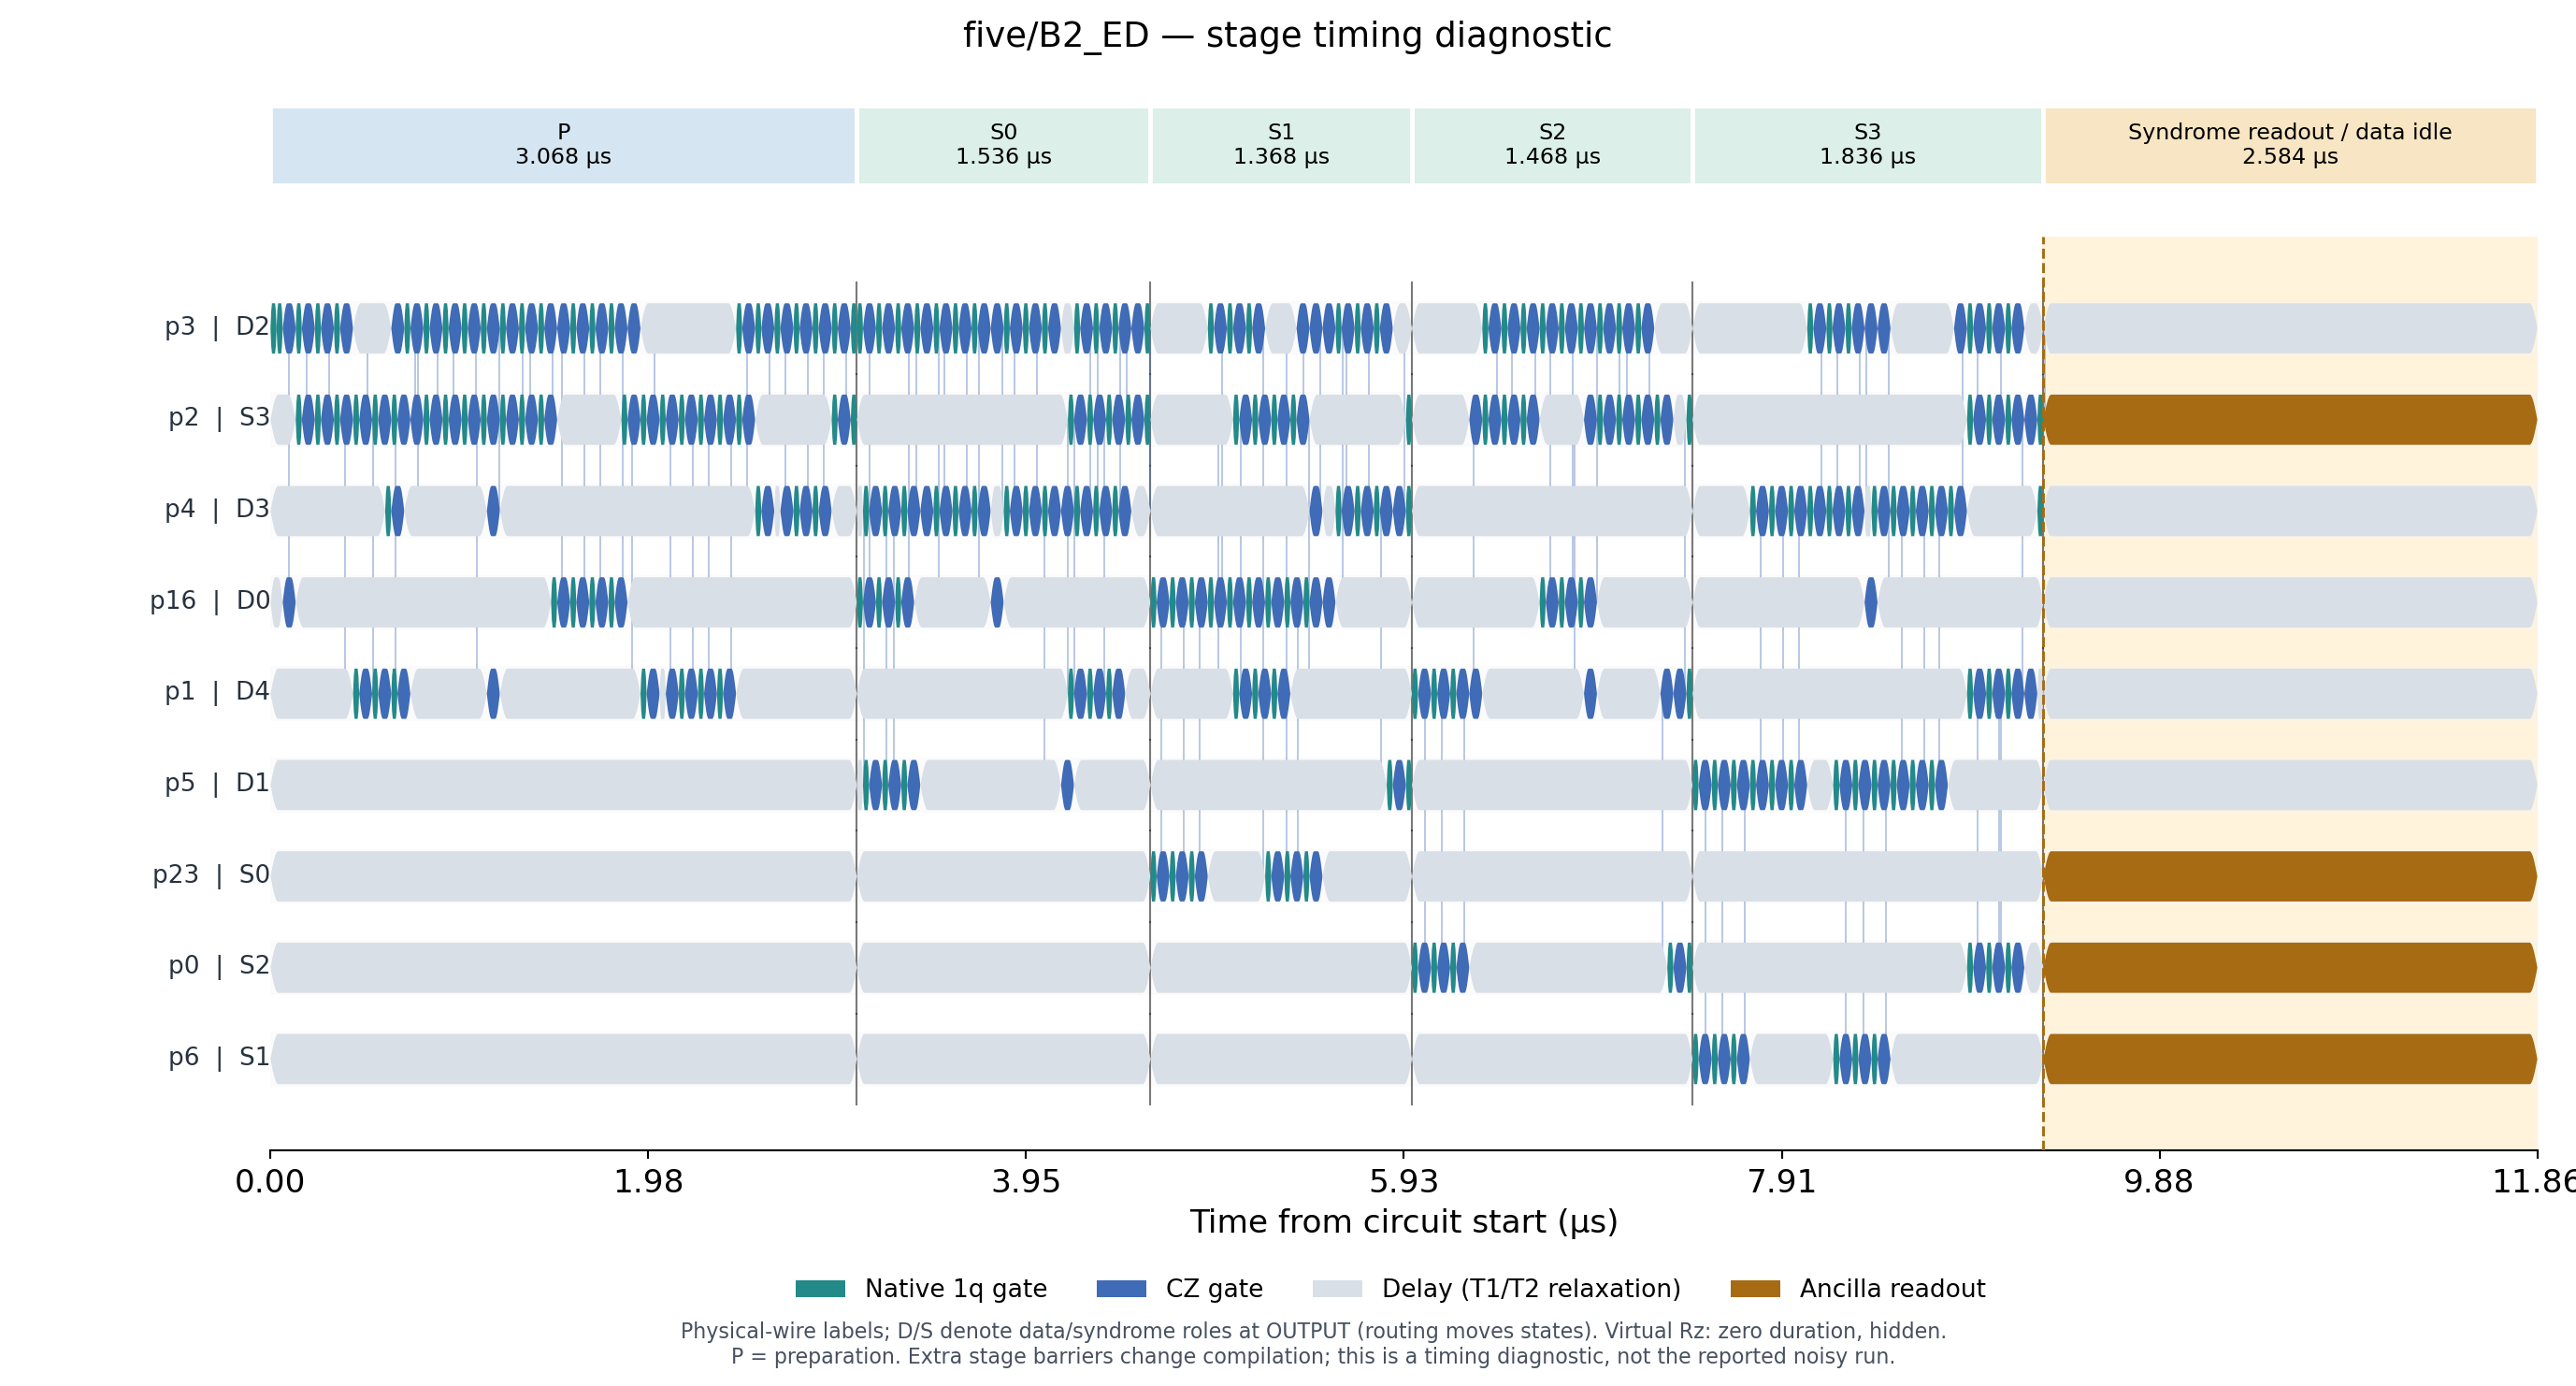

| Source stage | Duration (µs) |
|---|---:|
| prepare | 3.068 |
| check_0_XZZXI | 1.536 |
| check_1_IXZZX | 1.368 |
| check_2_XIXZZ | 1.468 |
| check_3_ZXIXZ | 1.836 |

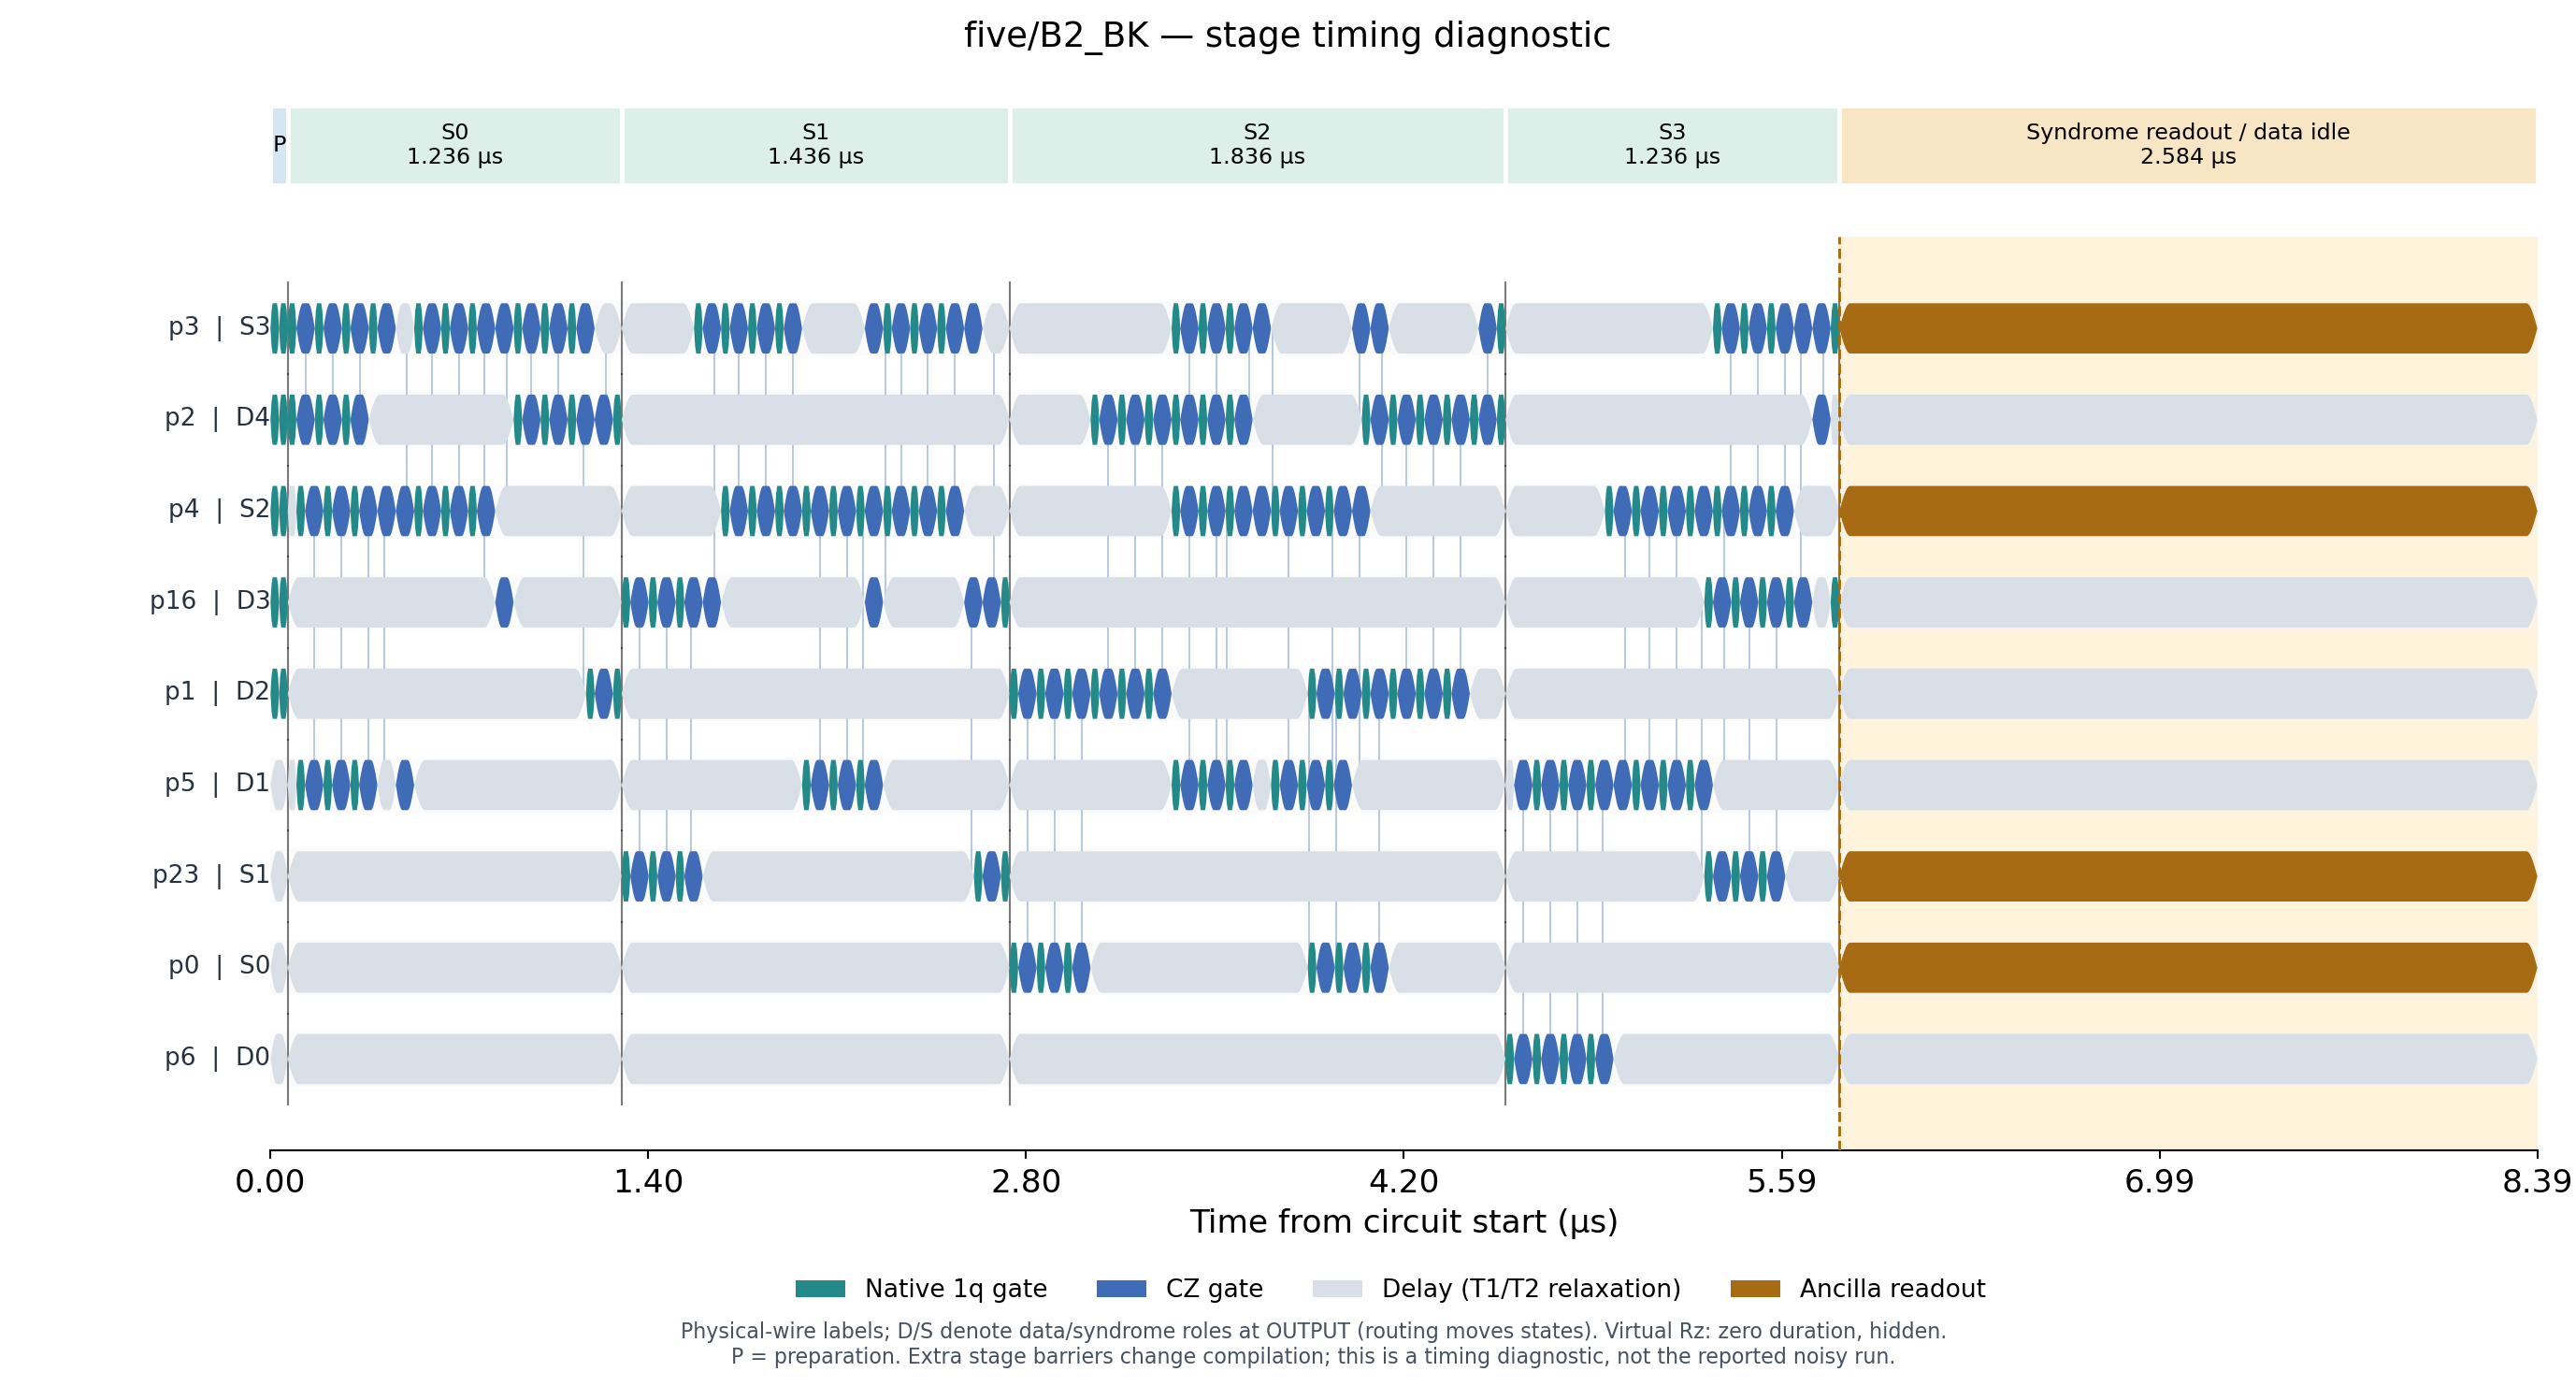

| Source stage | Duration (µs) |
|---|---:|
| prepare | 0.064 |
| check_0_XZZXI | 1.236 |
| check_1_IXZZX | 1.436 |
| check_2_XIXZZ | 1.836 |
| check_3_ZXIXZ | 1.236 |

In [14]:
table = ['| Protocol | Preparation (µs) | Check blocks (µs) | Readout (µs) | Checks + readout (µs) | Total (µs) |',
         '|---|---:|---:|---:|---:|---:|']
for row in timing['rows']:
    r = row['stage_diagnostic']
    assert np.isclose(r['ideal_validation']['fidelity'], 1)
    assert np.isclose(r['ideal_validation']['acceptance'], 1/6 if row['strategy'] == 'B2_BK' else 1)
    table.append(f"| {row['code']}/{row['strategy']} | {r['stages'][0]['duration_us']:.3f} | {r['syndrome_mapping_us']:.3f} | {r['readout_duration_us']:.3f} | {r['syndrome_mapping_and_readout_us']:.3f} | {r['total_us']:.3f} |")
display(Markdown('\n'.join(table)))
for row in timing['rows']:
    label = f"{row['code']}_{row['strategy']}"
    display(Image(filename=str(TIMELINES / (label + '_staged.png'))))
    checks = ['| Source stage | Duration (µs) |', '|---|---:|']
    for stage in row['stage_diagnostic']['stages']:
        checks.append(f"| {stage['stage']} | {stage['duration_us']:.3f} |")
    display(Markdown('\n'.join(checks)))

## 10. Remove delay noise only during syndrome extraction

This test disables **T1/T2 relaxation on Delay instructions from the end of
preparation/encoding through completion of syndrome readout**, on all physical
wires. It includes ancilla idles and the final data-qubit readout wait.
Preparation-phase delay noise, gate errors, gate-duration relaxation, and
syndrome readout assignment errors remain enabled. All gates and delays retain
their scheduled durations; no dynamical-decoupling pulses are inserted.

**Matched baseline:** the optimized original circuits have no clean preparation
boundary, so this test uses the **saved stage-separated circuits from Section 9**.
Their full-noise baseline is recomputed. The baseline and each ablation use the
same QPY circuit, routing, and timings; they are not compared against the earlier
original-circuit numbers. These additional stage barriers can change the noise
and performance of the circuit.

For the accepted state $\rho_A$ (recorded zero syndrome), define

$$p_{\rm code}=\mathrm{Tr}(P\rho_A),\qquad
F_{\rm code}=\frac{\langle\psi_L|P\rho_A P|\psi_L\rangle}{p_{\rm code}}.$$

These are the requested codespace population and fidelity within the codespace.
The full accepted-state fidelity is $F=p_{\rm code}F_{\rm code}$. This extra
codespace projection is a diagnostic only; it does not change the acceptance
rule or physically correct the delivered state.

**Arrows mean full noise → extraction/readout delay noise off.** These state
metrics come from exact density matrices, not finite-shot fidelity estimates.

In [15]:
from analyze_syndrome_delays import run_analysis as run_delay_analysis, comparison_table, modes_table

DELAY_ABLATION = OUTPUT / 'syndrome_delay_ablation'
RERUN_EXTRACTION_DELAYS = False
if RERUN_EXTRACTION_DELAYS or not (DELAY_ABLATION / 'results.json').exists():
    delay_study = run_delay_analysis(OUTPUT)
else:
    delay_study = json.loads((DELAY_ABLATION / 'results.json').read_text())
display(Markdown(comparison_table(delay_study)))
for row in delay_study['rows']:
    for mode in row['modes'].values():
        assert np.isclose(mode['fidelity'], mode['codespace_population'] * mode['fidelity_conditioned_on_codespace_diagnostic'])
    assert max(row['validation'].values()) < 1e-11
print('Explicit delay channels agree with the existing full/no-delay implementations.')

| Protocol | Codespace population | Fidelity within codespace | Full target fidelity | Acceptance |
|---|---:|---:|---:|---:|
| four/B2_ED | 94.172% → 98.439% | 99.761% → 99.780% | 93.948% → 98.223% | 89.863% → 91.216% |
| five/B2_ED | 88.567% → 94.464% | 99.134% → 99.153% | 87.800% → 93.664% | 65.481% → 68.531% |
| five/B2_BK | 82.929% → 91.307% | 99.656% → 99.720% | 82.643% → 91.051% | 14.630% → 14.932% |

Explicit delay channels agree with the existing full/no-delay implementations.


### Separate the final readout wait from earlier extraction idles

The readout-only control disables Delay relaxation only during the final
2.584 µs window. The extraction-only ablation additionally disables idle noise
during all stabilizer-mapping blocks. The all-delay-off control also removes
preparation idles, which remain noisy in the requested experiment.

The explicit-channel implementation is checked against the existing full-noise
and all-delay-off models, including density matrices and syndrome distributions.
Boundary-crossing delays retain the correct amount of preparation noise.
Readout-only suppression leaves exact acceptance unchanged. All 8,192-shot
syndrome counts per mode, per-delay noise durations, accepted density matrices,
and the frozen QPY inputs are saved in `results/noisy_aachen/syndrome_delay_ablation`.
This is a channel-removal diagnostic, not a prediction of DD performance.

In [16]:
display(Markdown(modes_table(delay_study)))
for row in delay_study['rows']:
    full = row['modes']['full']
    readout_off = row['modes']['readout_delay_off']
    assert np.isclose(full['acceptance'], readout_off['acceptance'], atol=1e-11, rtol=0)
    print(f"{row['code']}/{row['strategy']}: extraction starts at {row['timing']['extraction_start_us']:.3f} µs; output delivered at {row['timing']['delivery_us']:.3f} µs")

| Protocol | Model | Codespace population | Fidelity within codespace | Full target fidelity | Acceptance |
|---|---|---:|---:|---:|---:|
| four/B2_ED | Full noise | 94.172% | 99.761% | 93.948% | 89.863% |
| four/B2_ED | Readout-window delay noise off | 97.588% | 99.774% | 97.368% | 89.863% |
| four/B2_ED | Extraction + readout delay noise off | 98.439% | 99.780% | 98.223% | 91.216% |
| four/B2_ED | All delay noise off (control) | 98.442% | 99.813% | 98.258% | 91.385% |
| five/B2_ED | Full noise | 88.567% | 99.134% | 87.800% | 65.481% |
| five/B2_ED | Readout-window delay noise off | 92.041% | 99.137% | 91.246% | 65.481% |
| five/B2_ED | Extraction + readout delay noise off | 94.464% | 99.153% | 93.664% | 68.531% |
| five/B2_ED | All delay noise off (control) | 94.486% | 99.230% | 93.758% | 69.578% |
| five/B2_BK | Full noise | 82.929% | 99.656% | 82.643% | 14.630% |
| five/B2_BK | Readout-window delay noise off | 86.938% | 99.666% | 86.647% | 14.630% |
| five/B2_BK | Extraction + readout delay noise off | 91.307% | 99.720% | 91.051% | 14.932% |
| five/B2_BK | All delay noise off (control) | 91.307% | 99.720% | 91.051% | 14.932% |

four/B2_ED: extraction starts at 0.668 µs; output delivered at 6.088 µs
five/B2_ED: extraction starts at 3.068 µs; output delivered at 11.860 µs
five/B2_BK: extraction starts at 0.064 µs; output delivered at 8.392 µs


### Why does some accepted population still lie outside the code?

Extraction-delay suppression leaves noise on the gates themselves, including
gate-duration T1/T2 relaxation. The following controls use exactly the same
frozen circuits and start from the extraction-delay-off model in Section 10.
Each column removes the additional named channel; preparation noise remains
unless explicitly disabled in the detailed report.

**Every table entry below is the accepted population outside the code subspace.**
The controls identify extraction-gate noise as the main source of the residual
loss. A later faulty gate can damage data after a relevant stabilizer has already
been mapped onto an ancilla. That earlier parity is not measured again. Ancilla
gate faults can also corrupt the syndrome or propagate to data. Perfect classical
assignment cannot repair these quantum-circuit faults.

Ideal extraction gates plus ideal syndrome assignment restore unit codespace
population even with noisy preparation, because complete ideal stabilizer
projection rejects the outside-code component. The logical state inside the
code can still be distorted. These control differences are not additive source
fractions: changing noise can also change acceptance.

Here codespace loss stays inside the modeled two-level qubit Hilbert space;
physical leakage into higher transmon levels is not modeled.

In [17]:
from analyze_residual_codespace_loss import run_analysis as run_residual_analysis, summary_table as residual_table

residual_path = DELAY_ABLATION / 'residual_codespace_loss.json'
if residual_path.exists():
    residual = json.loads(residual_path.read_text())
else:
    residual = run_residual_analysis(DELAY_ABLATION)
display(Markdown(residual_table(residual)))
for row in residual['rows']:
    assert row['baseline_max_density_matrix_difference'] < 1e-11
    assert abs(row['modes']['perfect_extraction_gates_and_readout']['outside_code_population']) < 1e-11
    cz = row['modes']['perfect_extraction_cz']['outside_code_population']
    print(f"{row['code']}/{row['strategy']}: making extraction CZ gates ideal leaves {100*cz:.4f}% outside code (other gate noise and assignment errors retained).")

| Protocol | Extraction delay noise off | Also perfect readout | Also perfect extraction gates | Also perfect extraction gates + readout |
|---|---:|---:|---:|---:|
| four/B2_ED | 1.5606% | 1.5393% | 0.0048% | 0.0000% |
| five/B2_ED | 5.5355% | 4.8317% | 0.1464% | 0.0000% |
| five/B2_BK | 8.6928% | 7.9865% | 0.6976% | 0.0000% |

four/B2_ED: making extraction CZ gates ideal leaves 0.2437% outside code (other gate noise and assignment errors retained).
five/B2_ED: making extraction CZ gates ideal leaves 0.8156% outside code (other gate noise and assignment errors retained).
five/B2_BK: making extraction CZ gates ideal leaves 1.9094% outside code (other gate noise and assignment errors retained).


## 11. Restore full noise and test dynamical decoupling

This experiment uses **the original optimized saved Aachen circuits**, restoring
the baseline from Sections 3–8. The stage-separated circuits used for the phase
ablations have different baselines. Every variant here runs with **full noise**:
gate depolarization, gate-duration T1/T2 relaxation, relaxation during every
remaining Delay, and syndrome readout assignment errors. No ablation remains
active in this experiment.

Qiskit's `PadDynamicalDecoupling` inserts balanced **2-, 4-, or 8-X sequences**
inside sufficiently long idles. Native X pulses last 32 ns and include their
calibrated errors. The original gates, measurement times, and overall duration
are preserved. Initial ground-state idles are skipped, and short windows that
cannot fit the chosen sequence are left alone. All data qubits receive DD
during the 2.584 µs syndrome-readout window. The settings specify a pulse count
per eligible idle, not a uniform repetition rate across the full circuit.

The table gives **full accepted-state fidelity**, including codespace loss.
The no-DD replay matches the original saved density matrix, and all inserted
sequences preserve ideal target fidelity and acceptance.

| Protocol | No DD | 2 X / eligible idle | 4 X / eligible idle | 8 X / eligible idle |
|---|---:|---:|---:|---:|
| four/B2_ED | 94.3088% | 94.0653% | 93.9717% | 93.6507% |
| five/B2_ED | 88.6818% | 88.1138% | 87.6781% | 86.7702% |
| five/B2_BK | 85.4524% | 84.9841% | 84.5173% | 83.5599% |

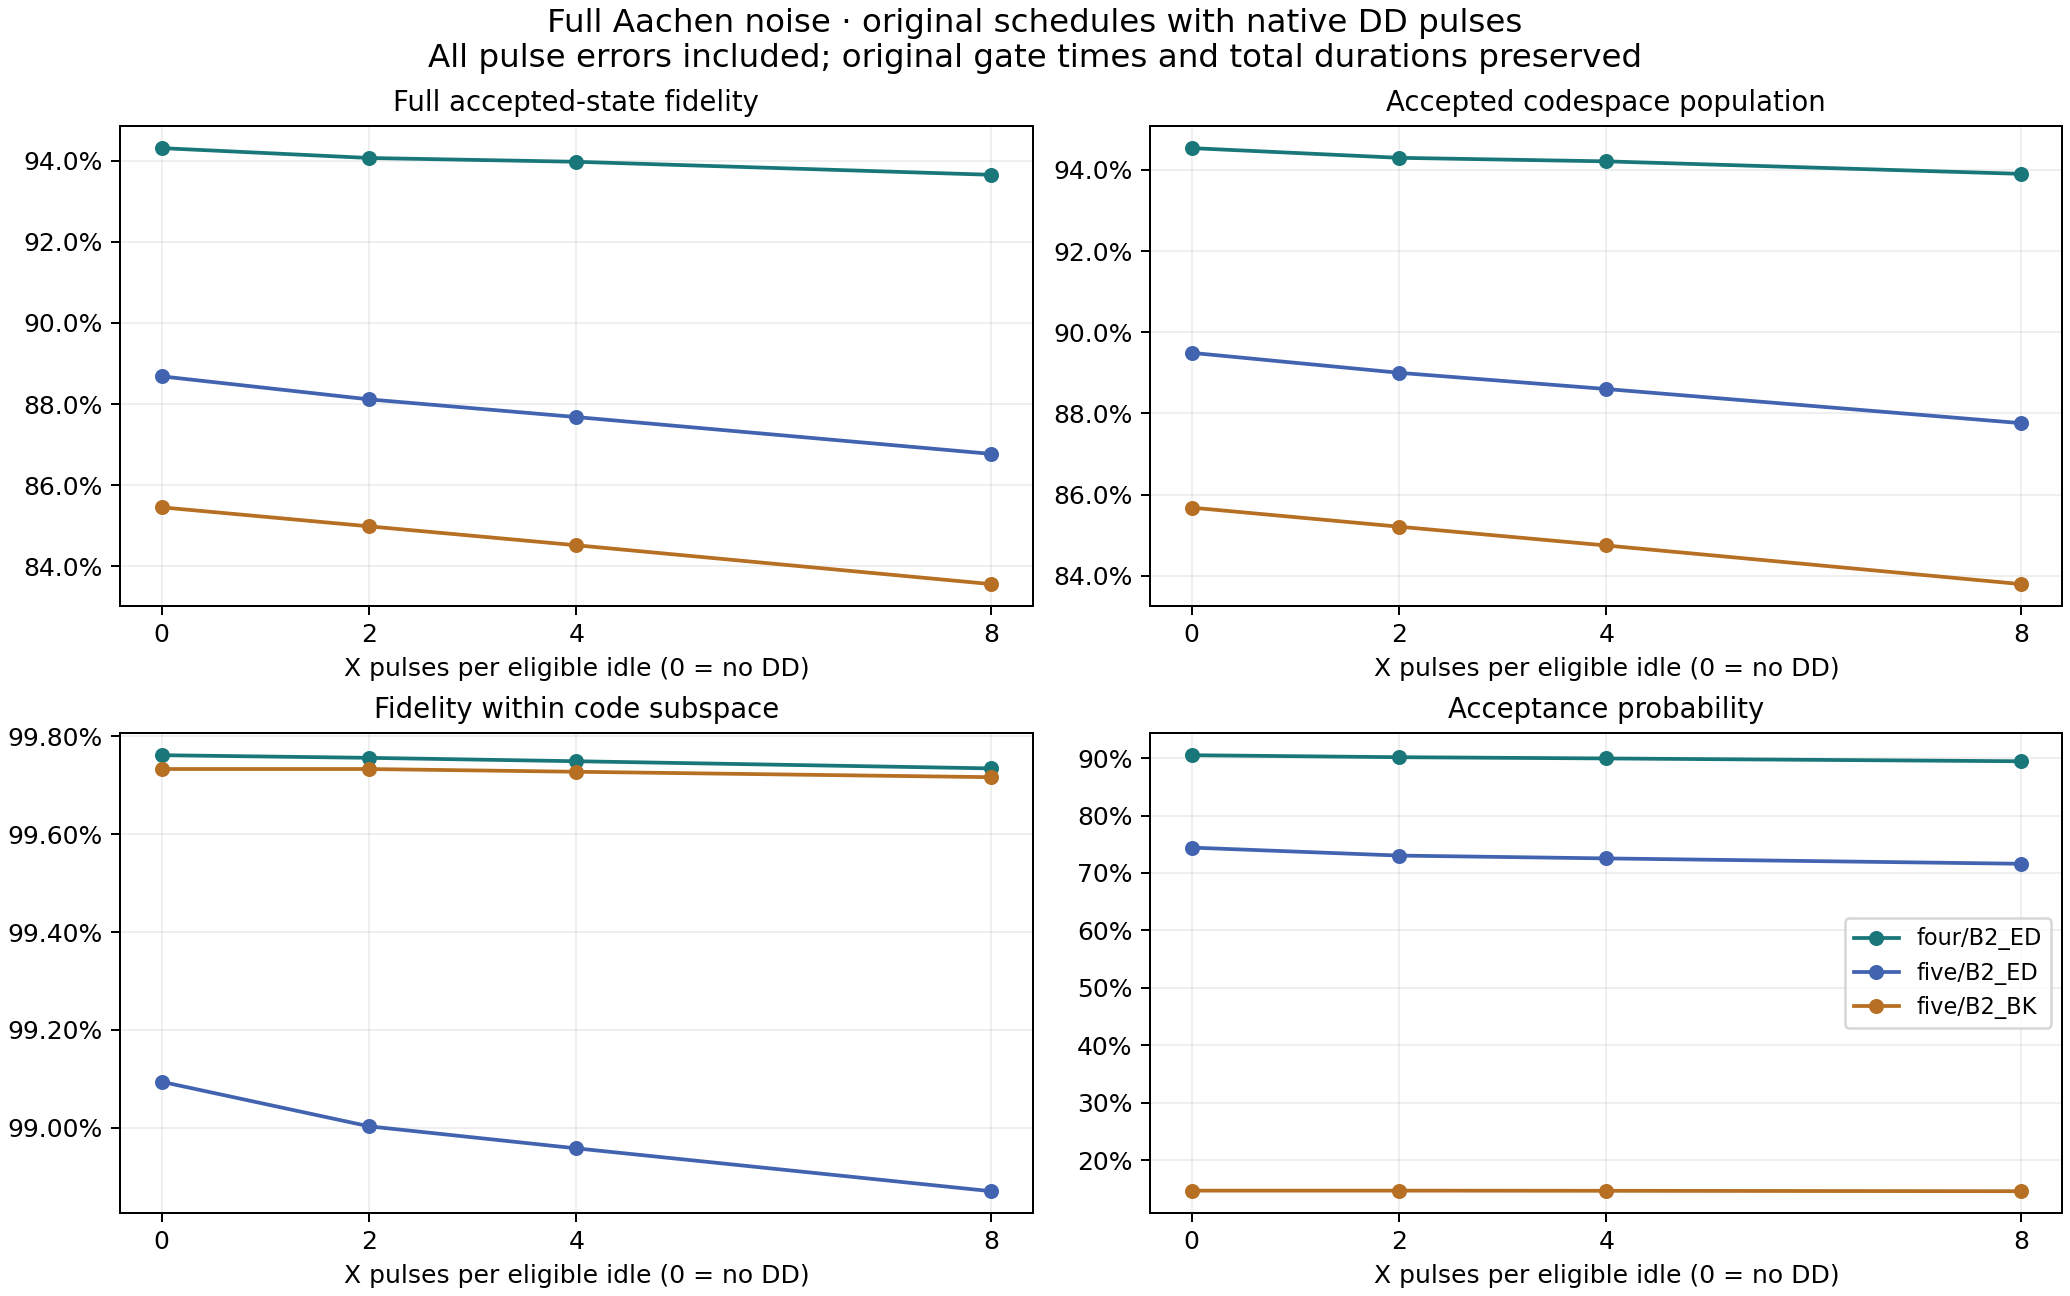

Full noise enabled for every DD variant; ideal references verified.


In [18]:
from analyze_dd import run_analysis as run_dd_analysis, fidelity_table as dd_fidelity_table, quality_table as dd_quality_table

DD_OUTPUT = OUTPUT / 'dd_full_noise'
RERUN_DD = False
if RERUN_DD or not (DD_OUTPUT / 'results.json').exists():
    dd_study = run_dd_analysis(OUTPUT)
else:
    dd_study = json.loads((DD_OUTPUT / 'results.json').read_text())
assert dd_study['noise_mode'] == 'full'
display(Markdown(dd_fidelity_table(dd_study)))
display(Image(filename=str(DD_OUTPUT / 'comparison.png')))
for row in dd_study['rows']:
    for name, variant in row['variants'].items():
        assert variant['metrics']['mode'] == 'full'
        assert np.isclose(variant['ideal_validation']['fidelity'], 1)
        assert np.isclose(variant['ideal_validation']['acceptance'], 1/6 if row['strategy'] == 'B2_BK' else 1)
print('Full noise enabled for every DD variant; ideal references verified.')

### Interpret the DD result in the noise model we actually have

The current calibrated idle model uses **memoryless exponential T1/T2 decay**.
It has no explicit slow detuning or temporal noise correlations. Those are
important for the phase-refocusing mechanism of DD. In these runs, additional
DD pulses lower fidelity; increasing pulse density adds further calibrated
gate noise. This is not evidence that DD cannot help the physical Aachen device.

For a one-qubit |+〉 state, ideal instantaneous X pulses leave the transverse
coherence at $\langle X\rangle=e^{-t/T_2}$ under this memoryless channel. The
sanity check below verifies this for zero, two, four, and eight pulses. A separate
constant-Z-detuning toy model refocuses exactly, showing that the echo sequence
works when the relevant coherent noise is present. **The toy model is not added
to the Aachen experiment and assumes no hardware detuning value.**

To assess DD's expected hardware benefit, the next modeling step is to separate
refocusable, correlated idle noise from irreversible relaxation, with measured
parameters or clearly stated sensitivity assumptions. Removing all Delay noise
is not a physical model of DD.

Sources: [IBM explanation of DD and slow noise](https://quantum.cloud.ibm.com/learning/en/courses/tools-for-quantum-advantage/error-suppression),
[Markovian limits of DD](https://arxiv.org/abs/1710.11133).

| Protocol | DD pulses per eligible idle | Added X gates | Protected idle windows | Codespace population | Within-code fidelity | Full fidelity | Acceptance |
|---|---:|---:|---:|---:|---:|---:|---:|
| four/B2_ED | 0 | 0 | 0 | 94.5341% | 99.7616% | 94.3088% | 90.5051% |
| four/B2_ED | 2 | 36 | 18 | 94.2951% | 99.7562% | 94.0653% | 90.1574% |
| four/B2_ED | 4 | 60 | 15 | 94.2079% | 99.7493% | 93.9717% | 89.9402% |
| four/B2_ED | 8 | 120 | 15 | 93.8999% | 99.7346% | 93.6507% | 89.4490% |
| five/B2_ED | 0 | 0 | 0 | 89.4925% | 99.0941% | 88.6818% | 74.4221% |
| five/B2_ED | 2 | 96 | 48 | 89.0011% | 99.0030% | 88.1138% | 73.0323% |
| five/B2_ED | 4 | 172 | 43 | 88.6013% | 98.9580% | 87.6781% | 72.5390% |
| five/B2_ED | 8 | 312 | 39 | 87.7615% | 98.8705% | 86.7702% | 71.6044% |
| five/B2_BK | 0 | 0 | 0 | 85.6809% | 99.7334% | 85.4524% | 14.7074% |
| five/B2_BK | 2 | 64 | 32 | 85.2112% | 99.7334% | 84.9841% | 14.7087% |
| five/B2_BK | 4 | 100 | 25 | 84.7480% | 99.7278% | 84.5173% | 14.6767% |
| five/B2_BK | 8 | 176 | 22 | 83.7973% | 99.7167% | 83.5599% | 14.6071% |

| Ideal instantaneous X pulses | Memoryless T1/T2: X coherence | Constant-detuning toy: X coherence |
|---:|---:|---:|
| 0 | 0.98983830 | 0.00000000 |
| 2 | 0.98983830 | 1.00000000 |
| 4 | 0.98983830 | 1.00000000 |
| 8 | 0.98983830 | 1.00000000 |

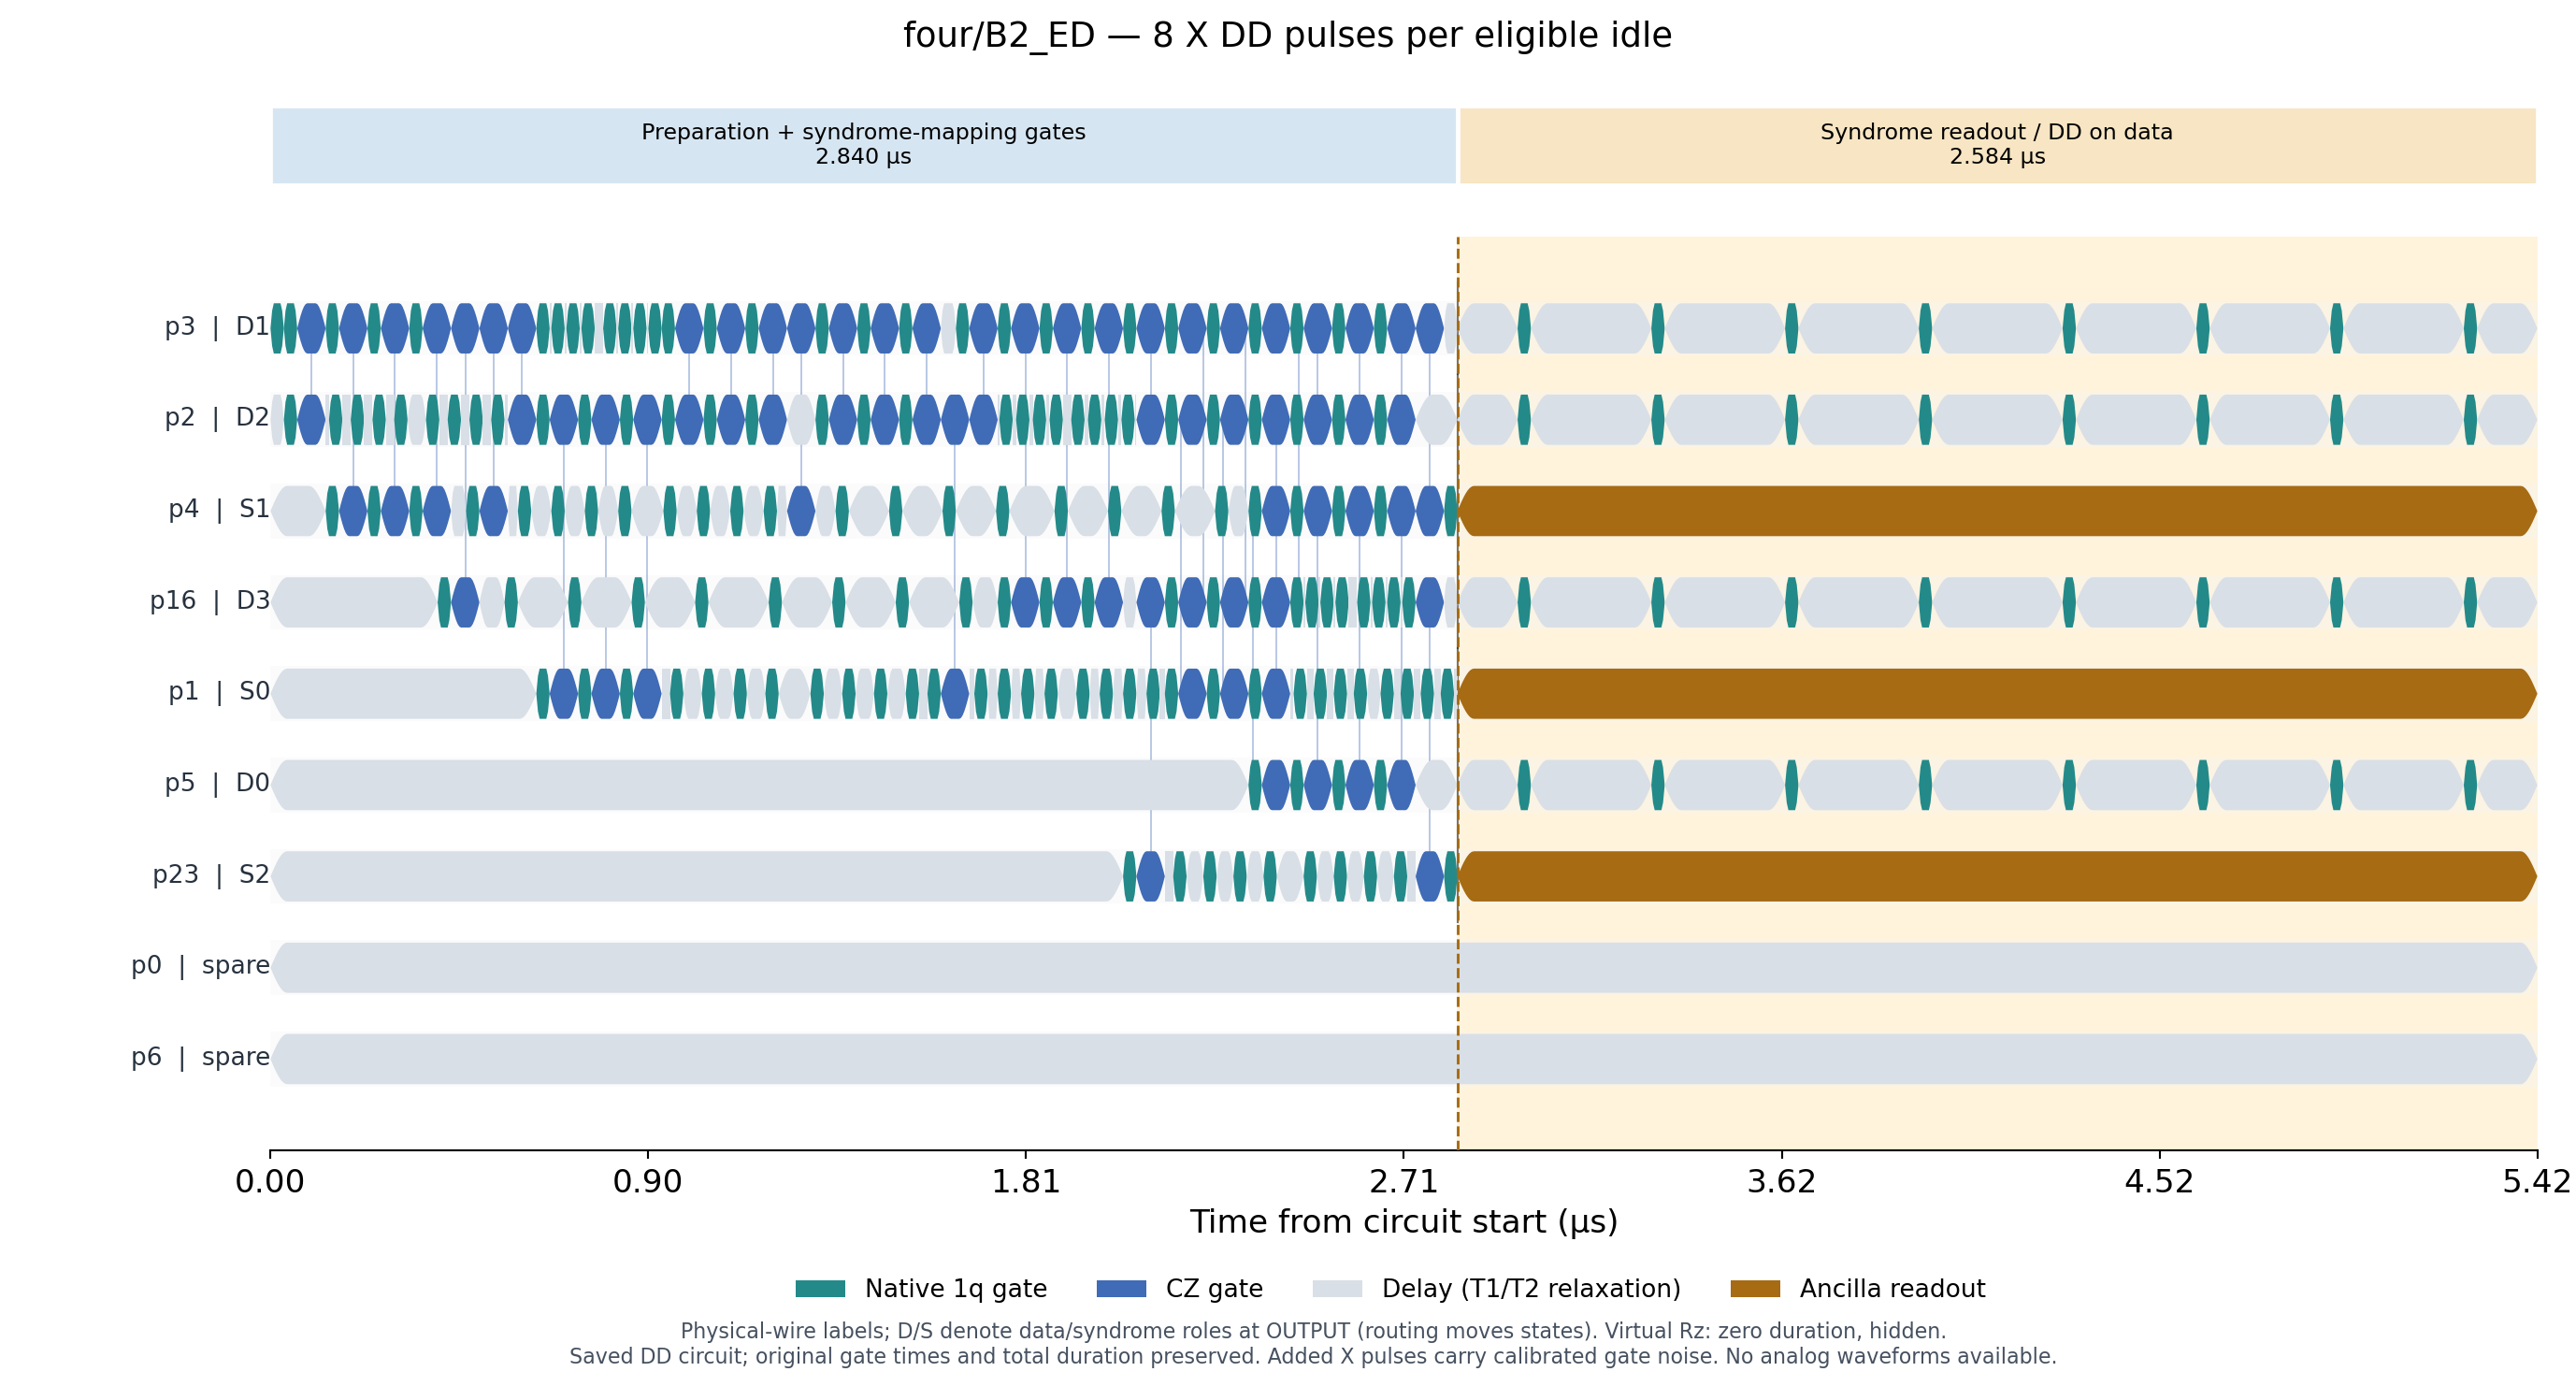

All three DD timelines and native QPY circuits are saved in: /Users/runzhemo/Desktop/Zhuang_group/hackathon/results/noisy_aachen/dd_full_noise


In [19]:
display(Markdown(dd_quality_table(dd_study)))
sanity = dd_study['echo_sanity']
table = ['| Ideal instantaneous X pulses | Memoryless T1/T2: X coherence | Constant-detuning toy: X coherence |',
         '|---:|---:|---:|']
for row in sanity['rows']:
    assert np.isclose(row['markovian_x_coherence'], sanity['expected_markovian_x_coherence'], atol=1e-12, rtol=0)
    table.append(f"| {row['ideal_instantaneous_x_pulses']} | {row['markovian_x_coherence']:.8f} | {row['constant_detuning_toy_x_coherence']:.8f} |")
display(Markdown('\n'.join(table)))
display(Image(filename=str(DD_OUTPUT / 'four_B2_ED_x8_timeline.png')))
print('All three DD timelines and native QPY circuits are saved in:', DD_OUTPUT)

## 12. Earlier readout and representative check-order changes

Ordinary `measure` and IBM `MidCircuitMeasure` implement the same logical
Z-basis measurement. A measurement is *mid-circuit* when computation continues
after it; ordinary `measure` can also be used in that position. IBM's special
`MidCircuitMeasure` maps to `measure_2` and is tuned for lower overhead during
ongoing computation. The actual duration and errors depend on calibration.
Our Aachen snapshot only exposes ordinary `measure`, lasting 2.584 µs on this
patch. We retain that duration; no faster measurement is assumed.
[IBM measurement documentation](https://quantum.cloud.ibm.com/docs/en/guides/execute-dynamic-circuits).

First, the exact original native circuits are retimed without changing gates,
physical mapping, or per-wire operation order:

1. Original simultaneous terminal readout.
2. Read each ancilla after its last gate, keeping all gate times fixed.
3. Move gates as early as dependencies allow (ASAP), then read ancillas early.
4. Keep those early readout deadlines but move gates as late as possible (ALAP).

All data idles through final delivery, pre-readout ancilla idles, gate noise, and
assignment errors remain enabled. After an ancilla is measured, its subsequent
relaxation cannot alter the stored bit. The exact deferred-measurement analysis
therefore discards only those unused, already-measured ancilla idles and rejects
any circuit that reuses a measured ancilla.

These are local-model candidate schedules. The model omits measurement-induced
crosstalk and does not certify hardware controller/readout-group constraints on
overlapping measurements with other gates. No hardware job is submitted.

In [20]:
from analyze_syndrome_schedules import (
    run_analysis as run_schedule_analysis, summary_table as schedule_table,
    timing_table as schedule_timing_table, check_order_table,
)

SCHEDULE_OUTPUT = OUTPUT / 'syndrome_schedules'
RERUN_SCHEDULES = False
if RERUN_SCHEDULES or not (SCHEDULE_OUTPUT / 'results.json').exists():
    schedule_study = run_schedule_analysis(OUTPUT)
else:
    schedule_study = json.loads((SCHEDULE_OUTPUT / 'results.json').read_text())
assert schedule_study['noise_mode'] == 'full'
display(Markdown(schedule_table(schedule_study)))
for row in schedule_study['rows']:
    original = row['variants']['original']
    for variant in row['variants'].values():
        assert np.isclose(variant['ideal_validation']['fidelity'], 1, atol=1e-11, rtol=0)
        assert np.isclose(variant['ideal_validation']['acceptance'], 1/6 if row['strategy'] == 'B2_BK' else 1, atol=1e-11, rtol=0)
        assert np.isclose(variant['resources']['duration_seconds'], original['resources']['duration_seconds'], atol=1e-13, rtol=0)
    assert np.isclose(row['variants']['fixed']['metrics']['unconditional_fidelity'],
                      original['metrics']['unconditional_fidelity'], atol=1e-11, rtol=0)
print('Exact state metrics at delivery; 8,192 sampled syndromes per schedule are saved separately.')

| Protocol | Schedule | Delivery (µs) | Acceptance | Codespace population | Within-code fidelity | Full fidelity |
|---|---|---:|---:|---:|---:|---:|
| four/B2_ED | Original | 5.424 | 90.5051% | 94.5341% | 99.7616% | 94.3088% |
| four/B2_ED | Early readout; fixed gates | 5.424 | 90.5022% | 94.5360% | 99.7617% | 94.3107% |
| four/B2_ED | Early readout; ASAP gates | 5.424 | 89.8241% | 94.0973% | 99.7595% | 93.8709% |
| four/B2_ED | Early readout; ALAP gates | 5.424 | 90.6116% | 94.4992% | 99.7617% | 94.2740% |
| five/B2_ED | Original | 10.396 | 74.4221% | 89.4925% | 99.0941% | 88.6818% |
| five/B2_ED | Early readout; fixed gates | 10.396 | 74.4111% | 89.5032% | 99.0942% | 88.6925% |
| five/B2_ED | Early readout; ASAP gates | 10.396 | 71.0635% | 89.0191% | 99.0865% | 88.2059% |
| five/B2_ED | Early readout; ALAP gates | 10.396 | 74.3528% | 89.5031% | 99.0944% | 88.6925% |
| five/B2_BK | Original | 6.224 | 14.7074% | 85.6809% | 99.7334% | 85.4524% |
| five/B2_BK | Early readout; fixed gates | 6.224 | 14.7054% | 85.6925% | 99.7335% | 85.4641% |
| five/B2_BK | Early readout; ASAP gates | 6.224 | 14.5190% | 85.2421% | 99.7152% | 84.9994% |
| five/B2_BK | Early readout; ALAP gates | 6.224 | 14.7160% | 85.8826% | 99.7350% | 85.6549% |

Exact state metrics at delivery; 8,192 sampled syndromes per schedule are saved separately.


### What earlier readout changes

The last ancilla remains on the critical path in the frozen native circuits,
so early readout does not shorten their total delivery time. With fixed gate
times it mainly changes how faithfully the earlier syndrome is stored; the
unconditional data state is unchanged. Earlier checks still cannot detect later
data faults. Moving every gate earlier can prepare fragile states too soon and
worsen their exposure to noise. The deadline-based ALAP schedule avoids some of
that exposure; it can also move independent data-only gates into readout waits.
The timeline below shows the original and deadline-based ALAP schedules.

| Protocol | Schedule | Ancilla readout starts (µs, syndrome-bit order) | Delivery (µs) |
|---|---|---|---:|
| four/B2_ED | Original | 2.840, 2.840, 2.840 | 5.424 |
| four/B2_ED | Early readout; fixed gates | 2.440, 2.840, 2.840 | 5.424 |
| four/B2_ED | Early readout; ASAP gates | 2.440, 2.840, 2.540 | 5.424 |
| four/B2_ED | Early readout; ALAP gates | 2.440, 2.840, 2.540 | 5.424 |
| five/B2_ED | Original | 7.812, 7.812, 7.812, 7.812 | 10.396 |
| five/B2_ED | Early readout; fixed gates | 7.312, 6.944, 7.712, 7.812 | 10.396 |
| five/B2_ED | Early readout; ASAP gates | 5.372, 6.876, 7.712, 7.812 | 10.396 |
| five/B2_ED | Early readout; ALAP gates | 5.372, 6.876, 7.712, 7.812 | 10.396 |
| five/B2_BK | Original | 3.640, 3.640, 3.640, 3.640 | 6.224 |
| five/B2_BK | Early readout; fixed gates | 3.540, 3.640, 3.640, 3.640 | 6.224 |
| five/B2_BK | Early readout; ASAP gates | 3.540, 2.936, 3.272, 3.640 | 6.224 |
| five/B2_BK | Early readout; ALAP gates | 3.540, 2.936, 3.272, 3.640 | 6.224 |

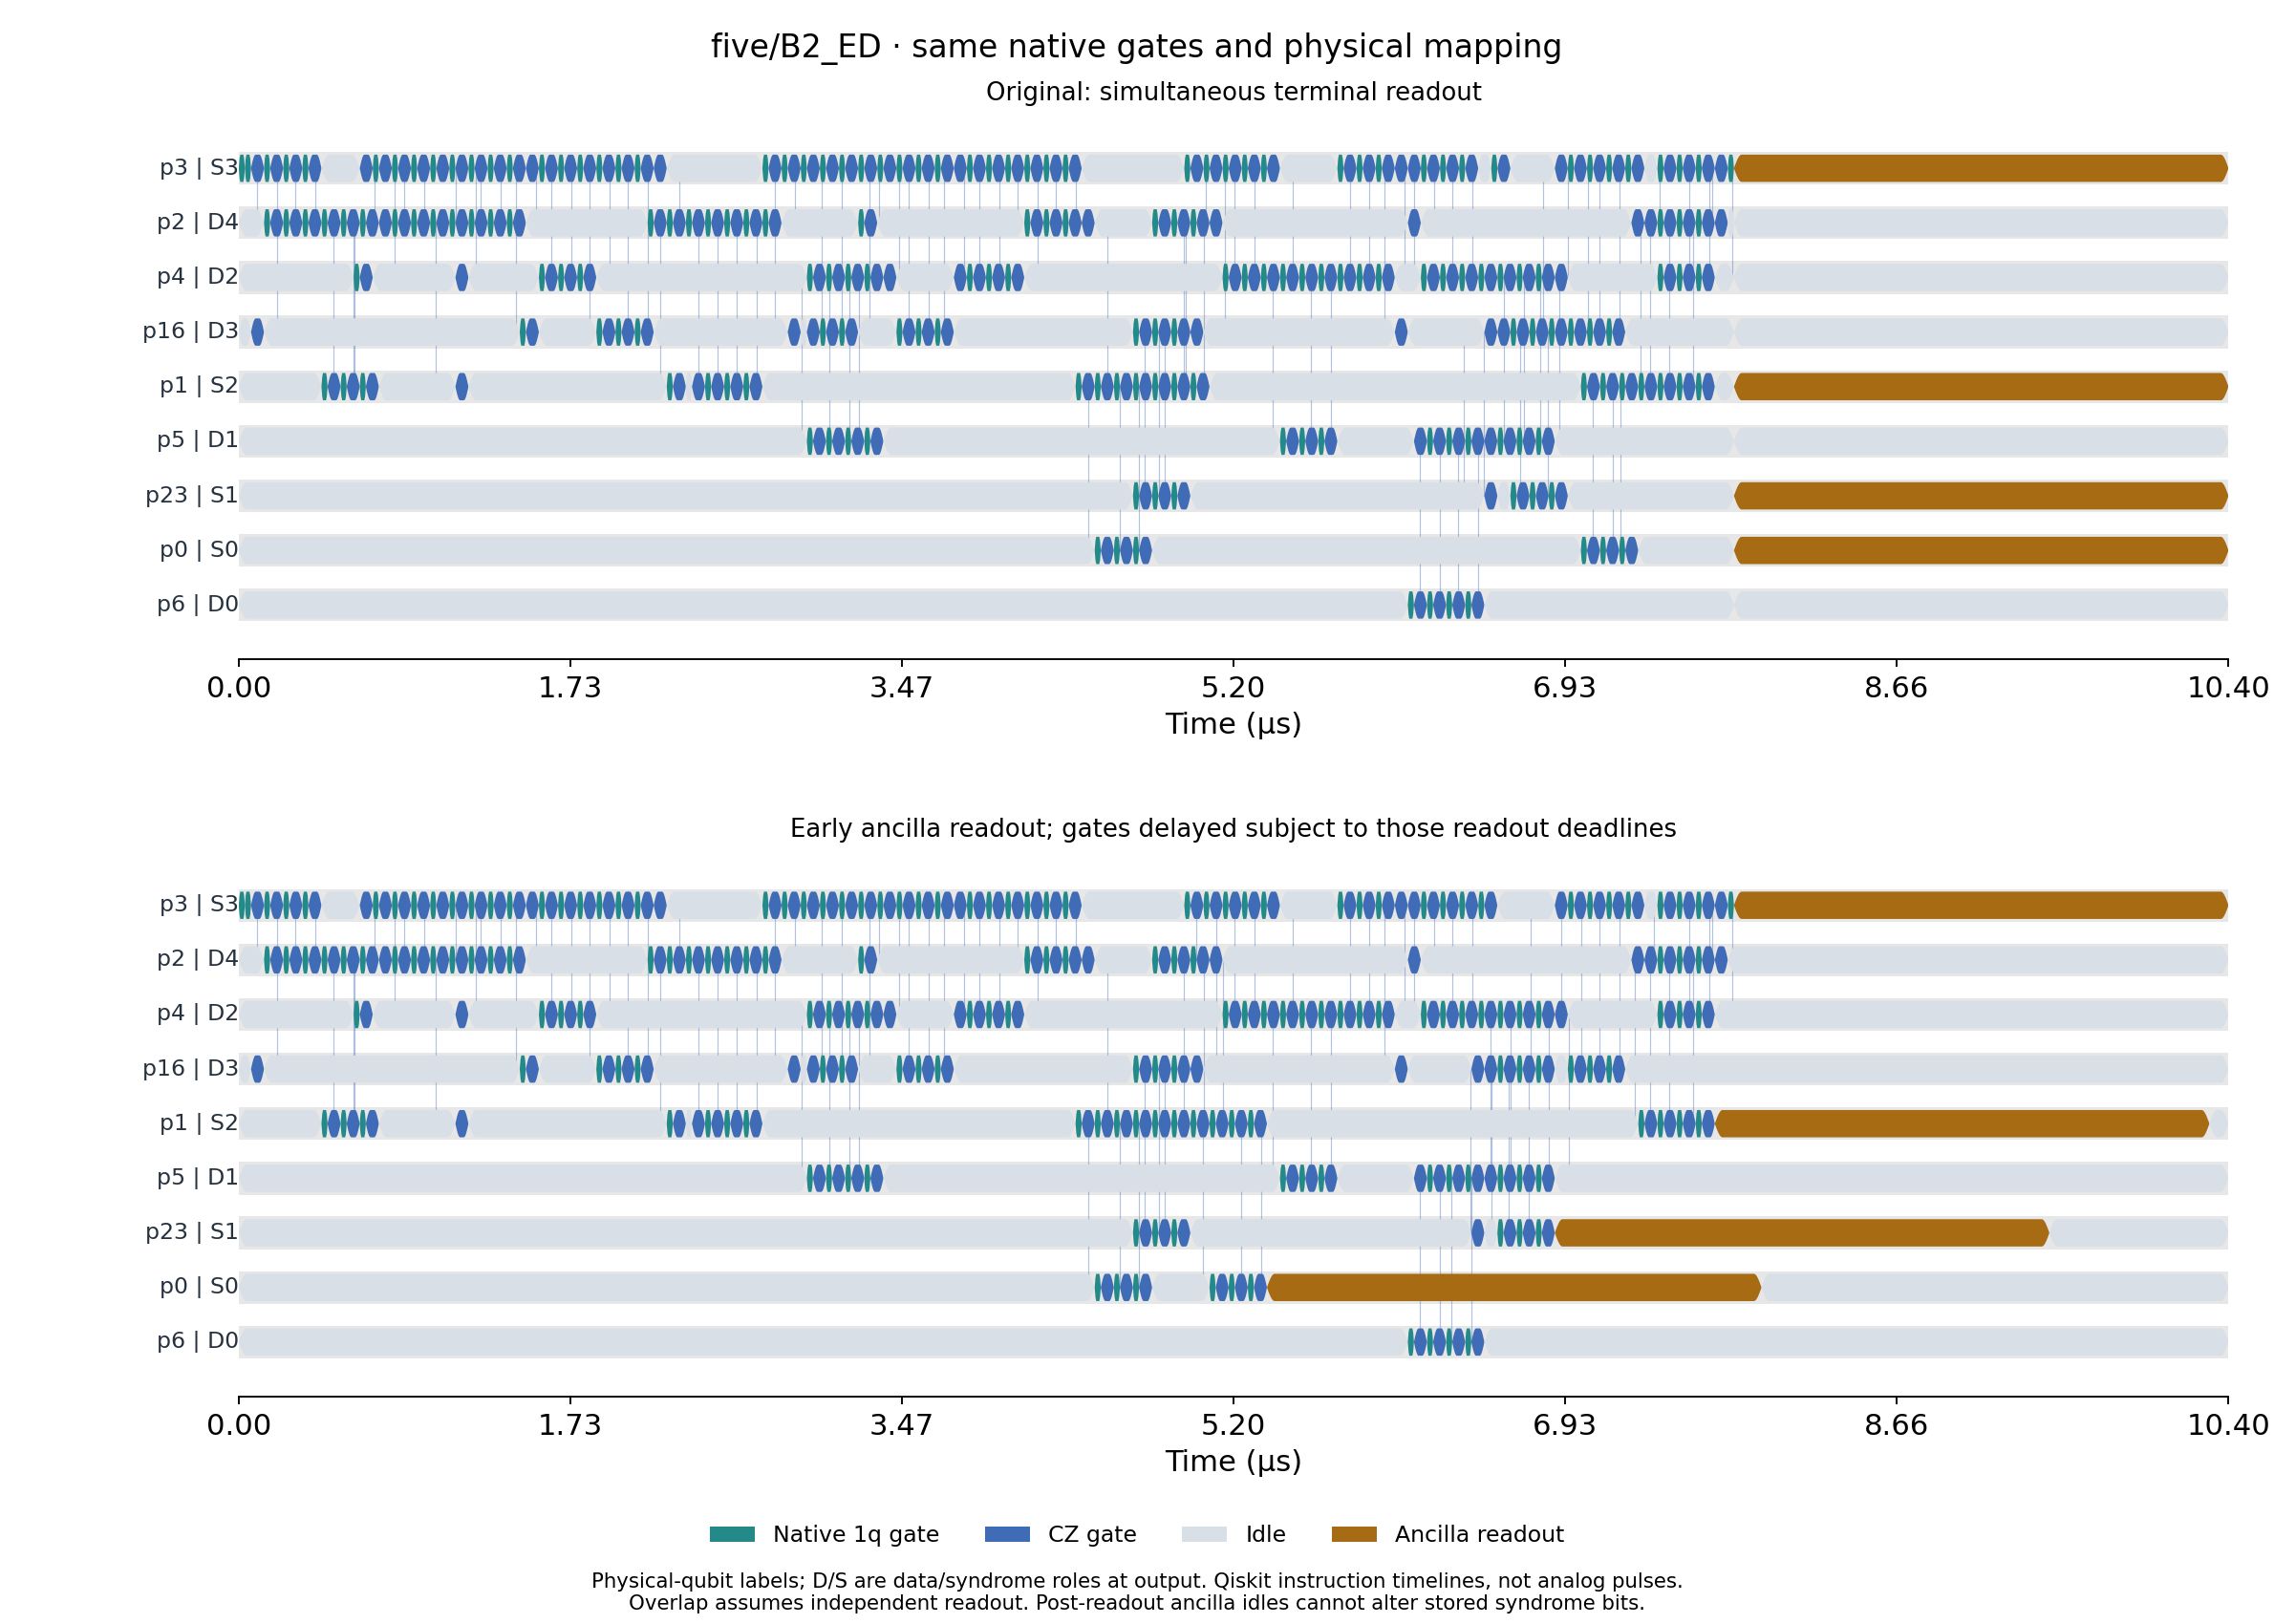

In [21]:
display(Markdown(schedule_timing_table(schedule_study)))
display(Image(filename=str(SCHEDULE_OUTPUT / 'five_B2_ED_timelines.png')))

### Change whole-check order: a separate matched compilation comparison

For each protocol we freeze one source preparation and try three whole-check
orders: reference, reverse, and a one-step rotation. Source preparation gates,
source ancilla assignments, initial placement, optimization level, and compiler
seed stay fixed. Gate count, routing, and final physical placement may change.
Whole stabilizer checks commute ideally; we do not arbitrarily interleave their
individual controlled-Pauli gates.

The newly compiled reference is the matched baseline for this table. It can
differ from the original archived circuit because encoder synthesis was not
frozen before the original run. The new source QPY is cached for reproduction.
Check indices refer to the stabilizer lists printed below. Each order has a
terminal-readout and an early deadline-based ALAP variant, both with full noise.
Fidelity is the complete accepted-state fidelity, including codespace loss.
Shorter circuits need not have better fidelity because routing changes which
physical gate and readout errors affect the data and acceptance.

In [22]:
display(Markdown(check_order_table(schedule_study)))
for row in schedule_study['order_study']:
    print(row['code'], row['strategy'], 'check indices:', dict(enumerate(row['checks_in_bit_order'])))
    for case in row['orders'].values():
        for variant in case['variants'].values():
            assert np.isclose(variant['ideal_validation']['fidelity'], 1, atol=1e-11, rtol=0)
            assert np.isclose(variant['ideal_validation']['acceptance'], 1/6 if row['strategy'] == 'B2_BK' else 1, atol=1e-11, rtol=0)
print('Saved report, states, native schedules, source circuits, and timelines:', SCHEDULE_OUTPUT)

| Protocol | Check execution order | Delivery (µs) | Terminal-readout fidelity | Early-readout fidelity | Early-readout codespace | Early-readout acceptance |
|---|---|---:|---:|---:|---:|---:|
| four/B2_ED | [0, 1, 2] | 5.424 | 94.3088% | 94.2740% | 94.4992% | 90.6116% |
| four/B2_ED | [2, 1, 0] | 5.252 | 93.8523% | 93.7873% | 94.0005% | 92.3082% |
| four/B2_ED | [1, 2, 0] | 5.252 | 93.8523% | 93.7873% | 94.0005% | 92.3082% |
| five/B2_ED | [0, 1, 2, 3] | 10.396 | 88.6818% | 88.6925% | 89.5031% | 74.3528% |
| five/B2_ED | [3, 2, 1, 0] | 9.528 | 89.5069% | 89.3949% | 89.7286% | 72.4200% |
| five/B2_ED | [1, 2, 3, 0] | 8.992 | 89.2383% | 89.2554% | 89.5749% | 74.6350% |
| five/B2_BK | [0, 1, 2, 3] | 6.224 | 85.4524% | 85.6549% | 85.8826% | 14.7160% |
| five/B2_BK | [3, 2, 1, 0] | 8.156 | 79.1976% | 79.2049% | 79.4480% | 13.3163% |
| five/B2_BK | [1, 2, 3, 0] | 6.524 | 84.7736% | 85.0115% | 85.2847% | 14.7181% |

four B2_ED check indices: {0: 'XXXX', 1: 'IIZZ', 2: 'ZZII'}
five B2_ED check indices: {0: 'XZZXI', 1: 'IXZZX', 2: 'XIXZZ', 3: 'ZXIXZ'}
five B2_BK check indices: {0: 'XZZXI', 1: 'IXZZX', 2: 'XIXZZ', 3: 'ZXIXZ'}
Saved report, states, native schedules, source circuits, and timelines: /Users/runzhemo/Desktop/Zhuang_group/hackathon/results/noisy_aachen/syndrome_schedules


## Scope and saved artifacts

This is a first noisy comparison of the existing bare circuits on one fixed
patch. It does not establish fault tolerance, optimal placement, or a hardware
advantage. B0 is a physical single-qubit output; encoded rows have different
resource costs and delivery times. B2_BK consumes five magic inputs. The model
omits drift, crosstalk, leakage, correlations, and downstream control latency.

Results are in `results/noisy_aachen`: a Markdown report, JSON metadata and raw
counts, accepted density matrices, a PNG/PDF comparison, exact QPY/text circuits,
and copied calibration files. `readout_and_fidelity.json` / `.md` add the
readout-only ablation, finite-shot measurement results, raw counts, statistical
intervals, and systematic-bias diagnostics. No IBM job is submitted and no
credentials are used.

`timelines/timing_report.md` and `timing_summary.json` add the Qiskit timing
figures and instruction timestamps. Diagnostic circuits with stage barriers
are saved separately in that folder.

`syndrome_delay_ablation/report.md` and `results.json` contain the matched
extraction-phase delay-noise ablation; its frozen inputs and accepted density
matrices are stored alongside them.
`syndrome_delay_ablation/residual_codespace_loss.md` adds separate extraction-gate,
CZ-gate, readout-assignment, and preparation-noise controls.
`dd_full_noise/report.md` adds full-noise DD results on the original circuits,
native DD circuit QPY files, pulse timestamps, timing plots, and model checks.
`syndrome_schedules/report.md` adds earlier readout, native-gate retiming, and
three representative whole-check orders, with full noise and saved timelines.

References: [FakeAachen](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider-fake-aachen),
[Aer NoiseModel](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html),
[RelaxationNoisePass](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.RelaxationNoisePass.html).